#**Optimizing Marketing Strategies based on Regional Product Trends in a Super App Company through Time Series Forecasting**
##**Dakota Group (8A) :**

*   Ahmad Galih Nur Jati
*   Fauzan Khairullah Umaternate
*   Farah Nabila
*   Karina Sukma Ardani
*   Oziva Achtar Chamely
*   Rebecca Yulyartha Bulawan Sihombing



#**Data Import**

In [ ]:
import os
print(os.listdir("/content/drive/MyDrive/"))

['PXL_20250307_074021733.jpg', 'Screenshot_2021-08-28-15-42-53-472_com.android.chrome.jpg', 'Untitled form (2).gform', 'Untitled form (Responses) (1).gsheet', 'absen edisi 2.jpeg', 'Classroom', 'Untitled document (8).gdoc', 'st30_Ahmad Galih Nur Jati.pdf', 'IMG_20211018_181335.jpg', 'Kelompok 23_Contoh Leadership (1).pdf', 'Kelompok 23_Contoh Leadership.pdf', 'THA05-Pengbis-21082010107-21082010125.gdoc', 'THA06-Pengbis-21082010107-21082010125.gdoc', 'absencod.jpeg', 'absenakhir cod.jpeg', 'THA07-Pengbis-21082010107-21082010125.gdoc', 'IJAZAH 21082010107.pdf', 'FORM PERNYATAAN ORANG TUA.pdf', 'UPN Veteran Jawa Timur.pdf', '21082010107_Ahmad Galih Nur Jati (4).pdf', 'UTS APB_Does ISO 9001 reinforce company performance? Evidence from Indonesian Industries.gdoc', 'Achieving Operational Excellence and Customer Intimacy  Enterprise Applications', 'VIdeo matkom educandy', 'Kelompok 6 - Educandy.docx', 'ISCOM_Circinus.rar', 'krs sem 2.jpeg', '21082010107_Ahmad Galih Nur Jati_English G610_Phras

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print(os.listdir("/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/"))

['Tim 8A - Python Notebook.ipynb', 'dataset-1', 'Forecasting Data', 'main_trx.csv']


In [ ]:
# Import library Panda
import pandas as pd
import os

**Data File : trx**

In [ ]:
#Read Dataframe untuk ditampilkan
directory = "/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/dataset-1/trx/"
files = os.listdir(directory)

main_trx = pd.DataFrame()
rows = 0
num_files = 0

print("Daftar file dalam direktori:")
for file in files:
  print(file)
  num_files += 1
  df = pd.read_csv(os.path.join(directory, file))
  rows += len(df)
  main_trx = pd.concat([main_trx, df], ignore_index=True)  # Concatenate the current DataFrame with the main DataFrame

print(f"Jumlah file : {num_files}")
print(f"No of rows : {rows}, length of main: {len(main_trx)}")

Daftar file dalam direktori:
34_processed.csv
71_processed.csv
81_processed.csv
99_processed.csv
36_processed.csv
64_processed.csv
51_processed.csv
19_processed.csv
82_processed.csv
75_processed.csv
65_processed.csv
62_processed.csv
12_processed.csv
17_processed.csv
76_processed.csv
16_processed.csv
74_processed.csv
73_processed.csv
53_processed.csv
18_processed.csv
72_processed.csv
52_processed.csv
61_processed.csv
11_processed.csv
15_processed.csv
63_processed.csv
13_processed.csv
21_processed.csv
14_processed.csv
31_processed.csv
35_processed.csv
33_processed.csv
32_processed.csv
95_processed.csv
94_processed.csv
92_processed.csv
93_processed.csv
96_processed.csv
91_processed.csv
Jumlah file : 39
No of rows : 12864324, length of main: 12864324


In [ ]:
main_trx

,id,user_id,product_id,gross_amount,discounts,transaction_date
0,TRX653289,SC3402052002003,1,15100.0,NaN,2024-06-09
1,TRX653290,SC3402052002003,1,17900.0,NaN,2024-06-03
2,TRX653291,SC3402052002003,1,10100.0,2000.0,2024-10-08
3,TRX653292,SC3402052002003,1,16900.0,8000.0,2024-10-09
4,TRX653293,SC3402052002003,2,10500.0,NaN,2024-01-08
...,...,...,...,...,...,...
12864319,TRX566727,SC9115142005001,9,53500.0,NaN,2024-08-17
12864320,TRX566728,SC9115142005001,12,22000.0,NaN,2024-11-17
12864321,TRX566729,SC9115142005001,12,76300.0,NaN,2024-10-19
12864322,TRX566730,SC9115142005001,12,71200.0,NaN,2024-09-13


**Data File : Product_references**

In [ ]:
# Membaca file CSV dengan delimiter tab
df_product = pd.read_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/dataset-1/product_reference.csv', delimiter=';')

# Menampilkan DataFrame
df_product

,id,product name
0,1,Man Fashion
1,2,Woman Fashion
2,3,Food & Drink
3,4,Ride Hailing
4,5,Keperluan Rumah Tangga
5,6,Travel
6,7,Keperluan Anak
7,8,Elektronik
8,9,Other
9,10,"Transportasi (Kereta, Pesawat, Kapal)"


**Data File : Location_references**

In [ ]:
df_loc = pd.read_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/dataset-1/location_reference.csv')
df_loc

,nama provinsi,kode provinsi,nama kabupaten,kode kabupaten,nama kecamatan,kode kecamatan
0,GORONTALO,75,BOALEMO,7502,BOTUMOITO,750206
1,GORONTALO,75,BOALEMO,7502,DULUPI,750203
2,GORONTALO,75,BOALEMO,7502,MANANGGU,750205
3,GORONTALO,75,BOALEMO,7502,PAGUYAMAN,750201
4,GORONTALO,75,BOALEMO,7502,PAGUYAMAN PANTAI,750207
...,...,...,...,...,...,...
7402,SUMATERA UTARA,12,TOBA,1212,SIANTAR NARUMONDA,121220
7403,SUMATERA UTARA,12,TOBA,1212,SIGUMPAR,121219
7404,SUMATERA UTARA,12,TOBA,1212,SILAEN,121203
7405,SUMATERA UTARA,12,TOBA,1212,TAMPAHAN,121222


**Data File : User**

In [ ]:
df_user = pd.read_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/dataset-1/user.csv')
df_user

,id,full_name,gender,money_spent,refund,wallet_balance,join_date,birth
0,SC7502062007001,PRIYANTI FIORI,perempuan,2270000.0,130000.0,480000.0,2023-11-05,1984-07-25
1,SC7502062007002,KURNIA MUHAMAD WANIMBO,laki-laki,2370000.0,140000.0,500000.0,2023-12-27,1991-02-12
2,SC7502062007003,AJENG LESTARI,perempuan,0.0,0.0,0.0,2024-07-19,1982-06-18
3,SC7502062007004,TIA IRIANI S.E.,perempuan,0.0,0.0,0.0,2024-05-24,1972-09-27
4,SC7502062006001,ANCE,perempuan,0.0,0.0,0.0,2024-11-25,1992-06-11
...,...,...,...,...,...,...,...,...
427481,SC1212102018001,ACHMAD,laki-laki,1040000.0,60000.0,360000.0,2023-10-14,1982-10-20
427482,SC1212102018004,AJIE AHMAD Masykur,laki-laki,1510000.0,60000.0,550000.0,2023-12-04,1997-08-03
427483,SC1212102008001,WIWIN WAHYUNI,perempuan,2120000.0,100000.0,800000.0,2023-12-10,1978-12-17
427484,SC1212102010001,NYIMAS,perempuan,1700000.0,50000.0,490000.0,2023-10-18,1993-04-04


#**Data Preprocessing**

**Team trx**

In [ ]:
# List semua kelompok nilai yang akan difilter
kode_provinsi_groups = [
    [35, 74, 75, 82],
    [32, 17, 18, 65],
    [32, 13, 14, 96],
    [35, 17, 18, 94],
    [33, 71, 72, 82],
    [33, 11, 12, 96],
    [32, 11, 12, 93],
    [33, 17, 18, 82],
    [35, 16, 17, 94],
    [32, 11, 12, 82],
    [32, 62, 63, 93],
    [33, 12, 13, 92],
    [32, 71, 72, 81],
    [32, 52, 53, 93],
    [32, 63, 64, 65],
    [35, 71, 72, 94],
    [35, 61, 62, 81],
    [33, 62, 63, 81],
    [33, 12, 13, 96],
    [35, 73, 74, 81],
    [33, 17, 18, 65],
    [35, 61, 62, 65],
    [33, 11, 12, 91],
    [35, 61, 62, 91],
    [32, 51, 52, 65],
    [35, 52, 53, 93],
    [35, 16, 17, 65],
    [35, 11, 12, 82],
    [35, 15, 16, 82],
    [35, 62, 63, 81],
    [33, 63, 64, 96],
    [32, 75, 76, 94],
    [35, 12, 13, 81],
    [33, 16, 17, 91],
    [35, 75, 76, 94],
    [33, 11, 12, 81],
    [33, 51, 52, 91],
    [33, 63, 64, 81],
    [33, 61, 62, 91],
    [32, 72, 73, 96],
    [35, 17, 18, 82],
    [33, 14, 15, 96],
    [33, 16, 17, 96],
    [35, 11, 12, 93],
    [32, 73, 74, 91],
    [35, 16, 17, 92],
    [35, 51, 52, 96],
    [32, 62, 63, 92],
    [33, 73, 74, 65],
    [35, 75, 76, 93],
    [33, 52, 53, 82],
    [35, 51, 52, 94],
    [35, 75, 76, 81],
    [32, 72, 73, 92],
    [33, 15, 16, 93],
    [33, 51, 52, 96],
    [35, 11, 12, 92],
    [35, 18, 19, 93],
    [32, 17, 18, 82],
    [32, 62, 63, 81],
    [33, 72, 73, 81],
    [33, 74, 75, 94],
    [35, 62, 63, 96],
    [32, 14, 15, 65],
    [35, 52, 53, 94],
    [33, 51, 52, 82],
    [33, 12, 13, 93],
    [33, 12, 13, 82],
    [32, 74, 75, 92],
    [33, 18, 19, 92],
    [35, 71, 72, 82],
    [35, 52, 53, 92],
    [32, 71, 72, 82],
    [32, 51, 52, 96],
    [32, 62, 63, 82],
    [35, 63, 64, 92],
    [35, 14, 15, 91],
    [32, 61, 62, 82],
    [32, 14, 15, 82],
    [32, 75, 76, 81],
    [35, 15, 16, 96],
    [33, 62, 63, 91],
    [35, 72, 73, 96],
    [33, 74, 75, 65],
    [32, 51, 52, 81],
    [35, 15, 16, 65],
    [32, 13, 14, 93],
    [35, 72, 73, 93],
    [35, 12, 13, 94],
    [35, 18, 19, 65],
    [32, 14, 15, 91],
    [32, 17, 18, 96],
    [35, 74, 75, 91],
    [32, 14, 15, 81],
    [35, 51, 52, 92],
    [35, 61, 62, 92],
    [32, 14, 15, 92],
    [32, 16, 17, 82],
    [35, 16, 17, 81],
    [32, 15, 16, 96],
    [32, 51, 52, 82],
    [33, 16, 17, 81],
    [33, 62, 63, 93],
    [35, 13, 14, 96],
    [33, 16, 17, 92],
    [32, 13, 14, 92],
    [35, 14, 15, 92],
    [32, 63, 64, 81],
    [33, 52, 53, 91],
    [32, 13, 14, 94],
    [32, 15, 16, 91],
    [33, 61, 62, 93]
]

# Drop duplicates based on 'kode provinsi'
unique_provinces_df = df_loc[['kode provinsi', 'nama provinsi']].drop_duplicates()

# Buat dictionary untuk memetakan kode provinsi ke nama provinsi
kode_to_nama_provinsi = dict(zip(unique_provinces_df['kode provinsi'], unique_provinces_df['nama provinsi']))

# Iterasi melalui setiap sublist dan cetak nama provinsi untuk setiap kode provinsi dalam sublist
for sublist in kode_provinsi_groups:
    provinsi_names = [kode_to_nama_provinsi[kode] for kode in sublist]
    print(provinsi_names)


['JAWA TIMUR', 'SULAWESI TENGGARA', 'GORONTALO', 'MALUKU UTARA']
['JAWA BARAT', 'BENGKULU', 'LAMPUNG', 'KALIMANTAN UTARA']
['JAWA BARAT', 'SUMATERA BARAT', 'RIAU', 'PAPUA BARAT DAYA']
['JAWA TIMUR', 'BENGKULU', 'LAMPUNG', 'PAPUA TENGAH']
['JAWA TENGAH', 'SULAWESI UTARA', 'SULAWESI TENGAH', 'MALUKU UTARA']
['JAWA TENGAH', 'ACEH', 'SUMATERA UTARA', 'PAPUA BARAT DAYA']
['JAWA BARAT', 'ACEH', 'SUMATERA UTARA', 'PAPUA SELATAN']
['JAWA TENGAH', 'BENGKULU', 'LAMPUNG', 'MALUKU UTARA']
['JAWA TIMUR', 'SUMATERA SELATAN', 'BENGKULU', 'PAPUA TENGAH']
['JAWA BARAT', 'ACEH', 'SUMATERA UTARA', 'MALUKU UTARA']
['JAWA BARAT', 'KALIMANTAN TENGAH', 'KALIMANTAN SELATAN', 'PAPUA SELATAN']
['JAWA TENGAH', 'SUMATERA UTARA', 'SUMATERA BARAT', 'PAPUA BARAT']
['JAWA BARAT', 'SULAWESI UTARA', 'SULAWESI TENGAH', 'MALUKU']
['JAWA BARAT', 'NUSA TENGGARA BARAT', 'NUSA TENGGARA TIMUR', 'PAPUA SELATAN']
['JAWA BARAT', 'KALIMANTAN SELATAN', 'KALIMANTAN TIMUR', 'KALIMANTAN UTARA']
['JAWA TIMUR', 'SULAWESI UTARA', 'SULAW

Berdasarkan data team trx yang ada, maka daerah yang dipilih adalah :
*   Level 1 :JAWA TIMUR
*   Level 2 :SUMATERA UTARA
*   Level 3 :SUMATERA BARAT
*   Level 4 : MALUKU



###1. Seleksi dataset processed berdasarkan region yang telah ditetapkan

In [ ]:
# Ekstrak kode lokasi dari user_id
main_trx['location_code'] = main_trx['user_id'].str.slice(2, 4)

# Data lokasi yang ingin Anda saring
desired_location_codes = [35, 12, 13, 81]

# Memfilter baris berdasarkan kode lokasi yang diinginkan
main_trx = main_trx[main_trx['location_code'].astype(int).isin(desired_location_codes)]

# Hapus kolom 'location_code' jika sudah tidak diperlukan
main_trx = main_trx.drop(columns=['location_code'])

main_trx

,id,user_id,product_id,gross_amount,discounts,transaction_date
306907,TRX668320,SC8104022023001,1,18500.0,NaN,2024-10-16
306908,TRX668321,SC8104022023001,1,120600.0,NaN,2024-02-03
306909,TRX668322,SC8104022023001,1,180900.0,30000.0,2024-02-06
306910,TRX668323,SC8104022023001,2,100300.0,NaN,2024-04-28
306911,TRX668324,SC8104022023001,2,21600.0,NaN,2024-04-14
...,...,...,...,...,...,...
8809028,TRX2704263,SC3504011002014,16,NaN,NaN,2024-09-11
8809029,TRX2704264,SC3504011002014,17,12400.0,NaN,2024-08-26
8809030,TRX2704265,SC3504011002014,17,4800.0,NaN,2024-02-25
8809031,TRX2704266,SC3504011002014,17,44300.0,NaN,2024-10-19


###2. Missing Value Data Processed (main_trx)

In [ ]:
main_trx.isnull().sum()

id                        0
user_id                   0
product_id                0
gross_amount          18457
discounts           2179117
transaction_date          0
dtype: int64

In [ ]:
#Penghapusan nilai Null pada kolom gross_amount
main_trx.dropna(subset=["gross_amount"], inplace=True)

In [ ]:
main_trx

,id,user_id,product_id,gross_amount,discounts,transaction_date
306907,TRX668320,SC8104022023001,1,18500.0,NaN,2024-10-16
306908,TRX668321,SC8104022023001,1,120600.0,NaN,2024-02-03
306909,TRX668322,SC8104022023001,1,180900.0,30000.0,2024-02-06
306910,TRX668323,SC8104022023001,2,100300.0,NaN,2024-04-28
306911,TRX668324,SC8104022023001,2,21600.0,NaN,2024-04-14
...,...,...,...,...,...,...
8809027,TRX2704262,SC3504011002014,16,20000.0,NaN,2024-07-01
8809029,TRX2704264,SC3504011002014,17,12400.0,NaN,2024-08-26
8809030,TRX2704265,SC3504011002014,17,4800.0,NaN,2024-02-25
8809031,TRX2704266,SC3504011002014,17,44300.0,NaN,2024-10-19


###3. Duplicate Data Processed (main_trx)

In [ ]:
#Melihat data yang duplikat pada dataframe secara keseluruhan
duplicate = main_trx.duplicated()
main_trx[duplicate]

,id,user_id,product_id,gross_amount,discounts,transaction_date


###4. Merge Data Processed (main_trx), Data product (df_product) using product_id

In [ ]:
merged_product = pd.merge(main_trx, df_product, left_on='product_id', right_on='id', how='left')

merged_product = merged_product.drop(columns=['id_y'])
merged_product.rename(columns={'id_x': 'id'}, inplace=True)

main_trx = merged_product

In [ ]:
main_trx

,id,user_id,product_id,gross_amount,discounts,transaction_date,product name
0,TRX668320,SC8104022023001,1,18500.0,NaN,2024-10-16,Man Fashion
1,TRX668321,SC8104022023001,1,120600.0,NaN,2024-02-03,Man Fashion
2,TRX668322,SC8104022023001,1,180900.0,30000.0,2024-02-06,Man Fashion
3,TRX668323,SC8104022023001,2,100300.0,NaN,2024-04-28,Woman Fashion
4,TRX668324,SC8104022023001,2,21600.0,NaN,2024-04-14,Woman Fashion
...,...,...,...,...,...,...,...
3095132,TRX2704262,SC3504011002014,16,20000.0,NaN,2024-07-01,Sewa Motor/Mobil
3095133,TRX2704264,SC3504011002014,17,12400.0,NaN,2024-08-26,Hotel
3095134,TRX2704265,SC3504011002014,17,4800.0,NaN,2024-02-25,Hotel
3095135,TRX2704266,SC3504011002014,17,44300.0,NaN,2024-10-19,Hotel


###5. Merge Data Processed (main_trx), and Data Location (df_loc) using user_id

In [ ]:
# Data lokasi yang ingin Anda saring
desired_location_codes = [35, 12, 13, 81]

# Memfilter baris berdasarkan kode lokasi yang diinginkan
df_loc = df_loc[df_loc['kode provinsi'].astype(int).isin(desired_location_codes)]

df_loc

,nama provinsi,kode provinsi,nama kabupaten,kode kabupaten,nama kecamatan,kode kecamatan
1876,MALUKU,81,BURU,8104,AIR BUAYA,810402
1877,MALUKU,81,BURU,8104,BATABUAL,810410
1878,MALUKU,81,BURU,8104,FENA LEISELA,810413
1879,MALUKU,81,BURU,8104,LILIALY,810415
1880,MALUKU,81,BURU,8104,LOLONG GUBA,810411
...,...,...,...,...,...,...
7402,SUMATERA UTARA,12,TOBA,1212,SIANTAR NARUMONDA,121220
7403,SUMATERA UTARA,12,TOBA,1212,SIGUMPAR,121219
7404,SUMATERA UTARA,12,TOBA,1212,SILAEN,121203
7405,SUMATERA UTARA,12,TOBA,1212,TAMPAHAN,121222


In [ ]:
# Mengambil karakter kedua hingga ketujuh dari user_id untuk mendapatkan kode kecamatan
main_trx['prov_code'] = main_trx['user_id'].str.slice(2, 4)
main_trx['kab_code'] = main_trx['user_id'].str.slice(2, 6)
main_trx['kec_code'] = main_trx['user_id'].str.slice(2, 8)

def remove_non_integer_kode_kabupaten(df, column_name):
    # Menggunakan to_numeric dengan errors='coerce' untuk mengubah nilai non-numerik menjadi NaN
    df[column_name] = pd.to_numeric(df[column_name], errors='coerce')
    # Menghapus baris yang mengandung NaN di kolom yang diberikan
    df = df.dropna(subset=[column_name])
    # Mengubah kolom menjadi tipe data integer
    df[column_name] = df[column_name].astype(int)
    return df

df_loc = remove_non_integer_kode_kabupaten(df_loc, 'kode provinsi')
df_loc = remove_non_integer_kode_kabupaten(df_loc, 'kode kabupaten')
df_loc = remove_non_integer_kode_kabupaten(df_loc, 'kode kecamatan')

main_trx = remove_non_integer_kode_kabupaten(main_trx, 'prov_code')
main_trx = remove_non_integer_kode_kabupaten(main_trx, 'kab_code')
main_trx = remove_non_integer_kode_kabupaten(main_trx, 'kec_code')

<ipython-input-19-d5b0b7ea9366>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[column_name] = pd.to_numeric(df[column_name], errors='coerce')


In [ ]:
# Melakukan merge berdasarkan kolom 'kode kecamatan'
merged_location = pd.merge(main_trx, df_loc[['kode kecamatan', 'nama provinsi', 'nama kabupaten', 'nama kecamatan']], left_on='kec_code', right_on='kode kecamatan', how='inner')

# Menghapus kolom 'location_code' dari main_trx
merged_location.drop(columns=['product_id','prov_code','kab_code','kec_code', 'kode kecamatan'], inplace=True)

main_trx = merged_location

In [ ]:
main_trx

,id,user_id,gross_amount,discounts,transaction_date,product name,nama provinsi,nama kabupaten,nama kecamatan
0,TRX668320,SC8104022023001,18500.0,NaN,2024-10-16,Man Fashion,MALUKU,BURU,AIR BUAYA
1,TRX668321,SC8104022023001,120600.0,NaN,2024-02-03,Man Fashion,MALUKU,BURU,AIR BUAYA
2,TRX668322,SC8104022023001,180900.0,30000.0,2024-02-06,Man Fashion,MALUKU,BURU,AIR BUAYA
3,TRX668323,SC8104022023001,100300.0,NaN,2024-04-28,Woman Fashion,MALUKU,BURU,AIR BUAYA
4,TRX668324,SC8104022023001,21600.0,NaN,2024-04-14,Woman Fashion,MALUKU,BURU,AIR BUAYA
...,...,...,...,...,...,...,...,...,...
3095132,TRX2704262,SC3504011002014,20000.0,NaN,2024-07-01,Sewa Motor/Mobil,JAWA TIMUR,TULUNGAGUNG,TULUNGAGUNG
3095133,TRX2704264,SC3504011002014,12400.0,NaN,2024-08-26,Hotel,JAWA TIMUR,TULUNGAGUNG,TULUNGAGUNG
3095134,TRX2704265,SC3504011002014,4800.0,NaN,2024-02-25,Hotel,JAWA TIMUR,TULUNGAGUNG,TULUNGAGUNG
3095135,TRX2704266,SC3504011002014,44300.0,NaN,2024-10-19,Hotel,JAWA TIMUR,TULUNGAGUNG,TULUNGAGUNG


### 6. Ubah tipe data transaction_date menjadi tipe data "datetime"

In [ ]:
main_trx['transaction_date'] = pd.to_datetime(main_trx['transaction_date'])

main_trx = main_trx.sort_values(by='transaction_date', ascending=False)
main_trx.head()

,id,user_id,gross_amount,discounts,transaction_date,product name,nama provinsi,nama kabupaten,nama kecamatan
1649143,TRX1249291,SC3578131002011,33800.0,NaN,2024-12-31,Woman Fashion,JAWA TIMUR,KOTA SURABAYA,BUBUTAN
1153876,TRX751328,SC3511122003005,5900.0,NaN,2024-12-31,Hotel,JAWA TIMUR,BONDOWOSO,WRINGIN
43831,TRX712314,SC8102012014009,15100.0,2800.0,2024-12-31,Investasi,MALUKU,MALUKU TENGGARA,KEI KECIL
232174,TRX874161,SC1205012014001,2700.0,NaN,2024-12-31,Keperluan Anak,SUMATERA UTARA,LANGKAT,BAHOROK
2543554,TRX2149558,SC3514012005006,148800.0,NaN,2024-12-31,Woman Fashion,JAWA TIMUR,PASURUAN,PURWODADI


###7. Perhitungan total_amount : gross_amount - discount

In [ ]:
# Replace NaN values in 'discount' column with 0
main_trx['discounts'].fillna(0, inplace=True)

# Membuat kolom baru 'total_amount'
main_trx['total_amount'] = main_trx['gross_amount'] - main_trx['discounts']

# Menghapus kolom 'gross_amount' dan 'discount'
main_trx.drop(['gross_amount', 'discounts'], axis=1, inplace=True)

# Verifikasi penghapusan kolom
main_trx.head()


,id,user_id,transaction_date,product name,nama provinsi,nama kabupaten,nama kecamatan,total_amount
1649143,TRX1249291,SC3578131002011,2024-12-31,Woman Fashion,JAWA TIMUR,KOTA SURABAYA,BUBUTAN,33800.0
1153876,TRX751328,SC3511122003005,2024-12-31,Hotel,JAWA TIMUR,BONDOWOSO,WRINGIN,5900.0
43831,TRX712314,SC8102012014009,2024-12-31,Investasi,MALUKU,MALUKU TENGGARA,KEI KECIL,12300.0
232174,TRX874161,SC1205012014001,2024-12-31,Keperluan Anak,SUMATERA UTARA,LANGKAT,BAHOROK,2700.0
2543554,TRX2149558,SC3514012005006,2024-12-31,Woman Fashion,JAWA TIMUR,PASURUAN,PURWODADI,148800.0


In [ ]:
# Mengganti nama kolom dengan karakter yang diizinkan
main_trx = main_trx.rename(columns={
    'product name': 'product_name',
    'nama provinsi': 'nama_provinsi',
    'nama kabupaten': 'nama_kabupaten',
    'nama kecamatan': 'nama_kecamatan'
})

In [ ]:
main_trx.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3095137 entries, 1649143 to 1778272
Data columns (total 8 columns):
 #   Column            Dtype         
---  ------            -----         
 0   id                object        
 1   user_id           object        
 2   transaction_date  datetime64[ns]
 3   product_name      object        
 4   nama_provinsi     object        
 5   nama_kabupaten    object        
 6   nama_kecamatan    object        
 7   total_amount      float64       
dtypes: datetime64[ns](1), float64(1), object(6)
memory usage: 212.5+ MB


In [ ]:
# Simpan DataFrame ke dalam file CSV
main_trx.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/main_trx.csv', index=False)


In [ ]:
pip install pandas-gbq

In [ ]:
import pandas as pd
from pandas.io import gbq

main_trx.to_gbq(destination_table='dakota_final.final_project',
                project_id='dakota-team-8a-final-project',
                if_exists='fail')

#**Exploratory Data Analyst**

###1. Jumlah Produk terjual berdasarkan kategori dalam Provinsi Jawa Timur

Kolom di transaksi_count_jatim: Index(['product_name', 'transaction_count'], dtype='object')
Jumlah data di transaksi_count_jatim: 18


<Figure size 1200x800 with 0 Axes>

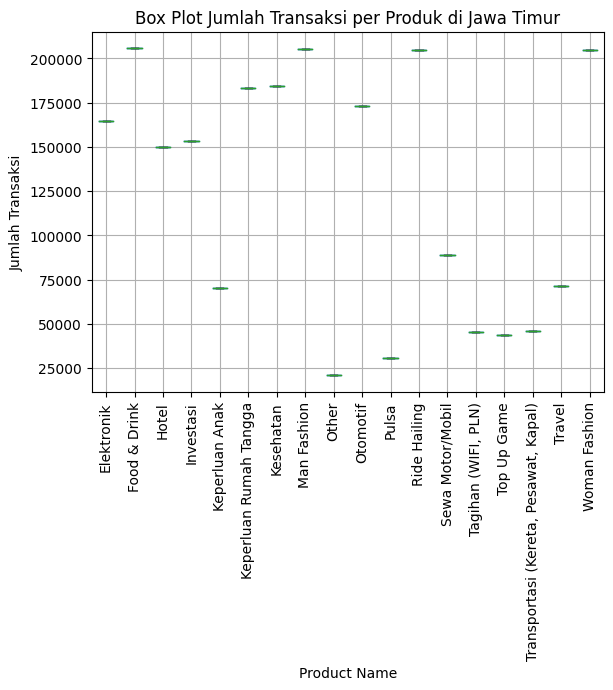

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Asumsikan 'main_trx' dan 'df_product' sudah ada dan memiliki data yang dibutuhkan

# Filter data transaksi untuk provinsi Jawa Timur
df_jatim = main_trx[main_trx['nama_provinsi'] == 'JAWA TIMUR']

# Menghitung jumlah transaksi per produk di Jawa Timur
transaksi_count_jatim = df_jatim['product_name'].value_counts().reset_index()
transaksi_count_jatim.columns = ['product_name', 'transaction_count']

# Verifikasi hasil perhitungan transaksi
print("Kolom di transaksi_count_jatim:", transaksi_count_jatim.columns)
print("Jumlah data di transaksi_count_jatim:", len(transaksi_count_jatim))

# Membuat box plot per kategori produk di Jawa Timur
plt.figure(figsize=(12, 8))  # Mengatur ukuran plot
boxplot_jatim = transaksi_count_jatim.boxplot(column='transaction_count', by='product_name', rot=90)

# Menambahkan label dan judul
boxplot_jatim.set_xlabel('Product Name')
boxplot_jatim.set_ylabel('Jumlah Transaksi')
plt.title('Box Plot Jumlah Transaksi per Produk di Jawa Timur')
plt.suptitle('')  # Menghapus judul default dari pandas

# Menampilkan plot
plt.show()


###2. Jumlah Produk terjual berdasarkan kategori dalam Provinsi Sumatera Utara

Kolom di transaksi_count_sumut: Index(['product_name', 'transaction_count'], dtype='object')
Jumlah data di transaksi_count_sumut: 18


<Figure size 1200x800 with 0 Axes>

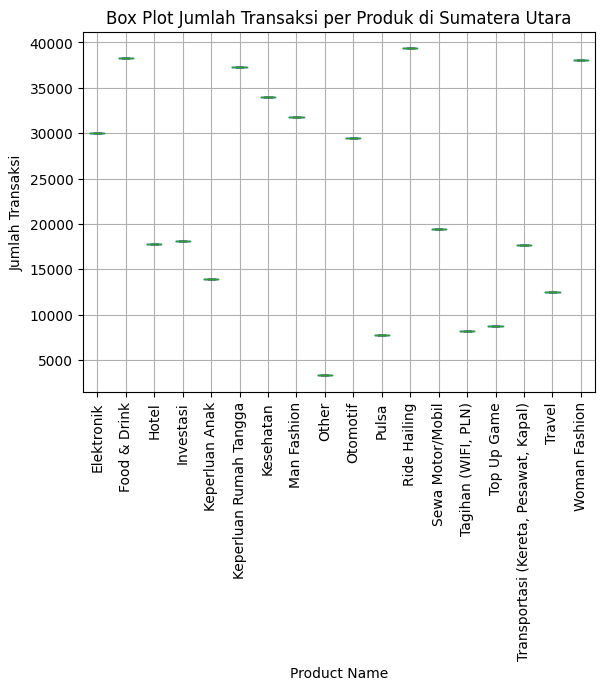

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter data transaksi untuk provinsi SUMATERA UTARA
df_sumut = main_trx[main_trx['nama_provinsi'] == 'SUMATERA UTARA']

# Menghitung jumlah transaksi per produk di Sumatera Utara
transaksi_count_sumut = df_sumut['product_name'].value_counts().reset_index()
transaksi_count_sumut.columns = ['product_name', 'transaction_count']

# Verifikasi hasil perhitungan transaksi
print("Kolom di transaksi_count_sumut:", transaksi_count_sumut.columns)
print("Jumlah data di transaksi_count_sumut:", len(transaksi_count_sumut))

# Membuat box plot per kategori produk di Sumatera Utara
plt.figure(figsize=(12, 8))  # Mengatur ukuran plot
boxplot_sumut = transaksi_count_sumut.boxplot(column='transaction_count', by='product_name', rot=90)

# Menambahkan label dan judul
boxplot_sumut.set_xlabel('Product Name')
boxplot_sumut.set_ylabel('Jumlah Transaksi')
plt.title('Box Plot Jumlah Transaksi per Produk di Sumatera Utara')
plt.suptitle('')  # Menghapus judul default dari pandas

# Menampilkan plot
plt.show()


###3. Jumlah Produk terjual berdasarkan kategori dalam Provinsi Sumatera Barat

Kolom di transaksi_count_sumbar: Index(['product_name', 'transaction_count'], dtype='object')
Jumlah data di transaksi_count_sumbar: 18


<Figure size 1200x800 with 0 Axes>

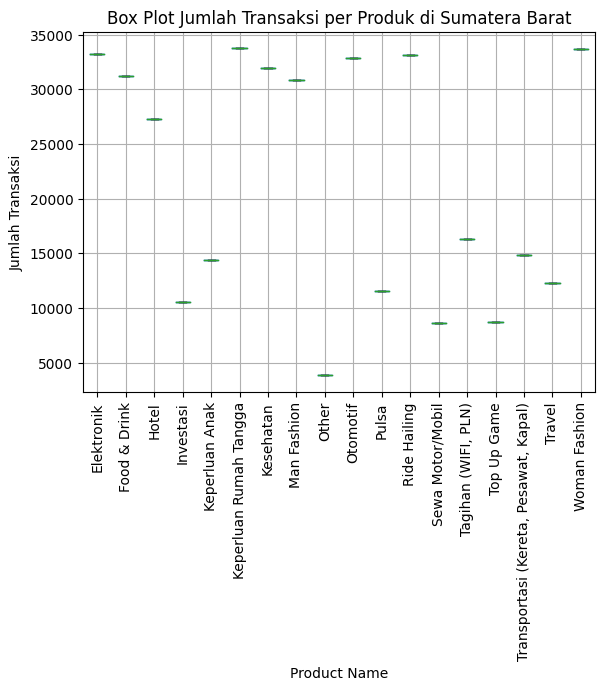

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter data transaksi untuk provinsi SUMATERA BARAT
df_sumbar = main_trx[main_trx['nama_provinsi'] == 'SUMATERA BARAT']

# Menghitung jumlah transaksi per produk di Sumatera Barat
transaksi_count_sumbar = df_sumbar['product_name'].value_counts().reset_index()
transaksi_count_sumbar.columns = ['product_name', 'transaction_count']

# Verifikasi hasil perhitungan transaksi
print("Kolom di transaksi_count_sumbar:", transaksi_count_sumbar.columns)
print("Jumlah data di transaksi_count_sumbar:", len(transaksi_count_sumbar))

# Membuat box plot per kategori produk di Sumatera Barat
plt.figure(figsize=(12, 8))  # Mengatur ukuran plot
boxplot_sumbar = transaksi_count_sumbar.boxplot(column='transaction_count', by='product_name', rot=90)

# Menambahkan label dan judul
boxplot_sumbar.set_xlabel('Product Name')
boxplot_sumbar.set_ylabel('Jumlah Transaksi')
plt.title('Box Plot Jumlah Transaksi per Produk di Sumatera Barat')
plt.suptitle('')  # Menghapus judul default dari pandas

# Menampilkan plot
plt.show()


###4. Jumlah Produk terjual berdasarkan kategori dalam Provinsi Maluku

Kolom di transaksi_count_maluku: Index(['product_name', 'transaction_count'], dtype='object')
Jumlah data di transaksi_count_maluku: 18


<Figure size 1200x800 with 0 Axes>

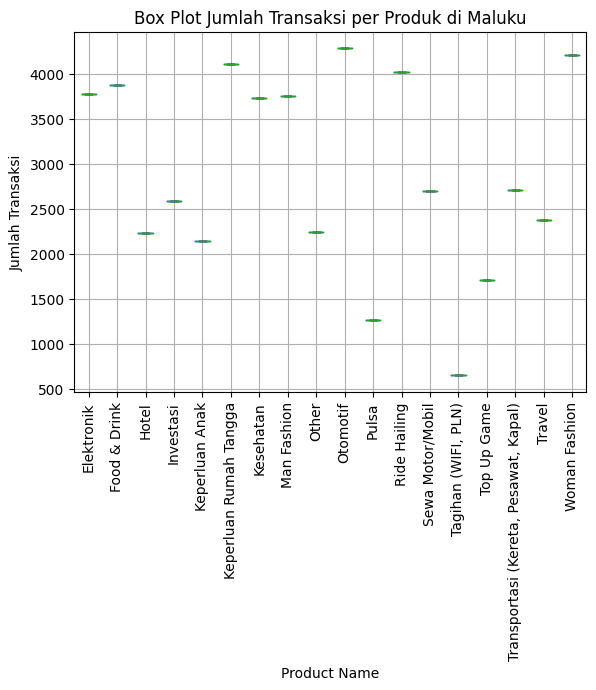

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter data transaksi untuk provinsi Maluku
df_maluku = main_trx[main_trx['nama_provinsi'] == 'MALUKU']

# Menghitung jumlah transaksi per produk di Maluku
transaksi_count_maluku = df_maluku['product_name'].value_counts().reset_index()
transaksi_count_maluku.columns = ['product_name', 'transaction_count']

# Verifikasi hasil perhitungan transaksi
print("Kolom di transaksi_count_maluku:", transaksi_count_maluku.columns)
print("Jumlah data di transaksi_count_maluku:", len(transaksi_count_maluku))

# Membuat box plot per kategori produk di Maluku
plt.figure(figsize=(12, 8))  # Mengatur ukuran plot
boxplot_maluku = transaksi_count_maluku.boxplot(column='transaction_count', by='product_name', rot=90)

# Menambahkan label dan judul
boxplot_maluku.set_xlabel('Product Name')
boxplot_maluku.set_ylabel('Jumlah Transaksi')
plt.title('Box Plot Jumlah Transaksi per Produk di Maluku')
plt.suptitle('')  # Menghapus judul default dari pandas

# Menampilkan plot
plt.show()


### 5. Membagi dataset berdasarkan 3 produk terbanyak dibeli dalam provinsi Jawa Timur

In [ ]:
# Filter data transaksi untuk masing-masing kategori produk di Jawa Timur
fooddrink_jatim_data = main_trx[(main_trx['product_name'] == 'Food & Drink') & (main_trx['nama_provinsi'] == 'JAWA TIMUR')]
manfashion_jatim_data = main_trx[(main_trx['product_name'] == 'Man Fashion') & (main_trx['nama_provinsi'] == 'JAWA TIMUR')]
ridehailing_jatim_data = main_trx[(main_trx['product_name'] == 'Ride Hailing') & (main_trx['nama_provinsi'] == 'JAWA TIMUR')]

# Kelompokkan data per minggu dan hitung jumlah product yang terjual dan total_amount tiap minggu
fooddrink_jatim = fooddrink_jatim_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
manfashion_jatim = manfashion_jatim_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
ridehailing_jatim = ridehailing_jatim_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()

# Ubah nama kolom untuk merepresentasikan jumlah product yang terjual
fooddrink_jatim.rename(columns={'id': 'product_count'}, inplace=True)
manfashion_jatim.rename(columns={'id': 'product_count'}, inplace=True)
ridehailing_jatim.rename(columns={'id': 'product_count'}, inplace=True)

# Verifikasi hasil
print("Data Food & Drink di Jawa Timur:")
print(fooddrink_jatim.head())

print("\nData Man Fashion di Jawa Timur:")
print(manfashion_jatim.head())

print("\nData Ride Hailing di Jawa Timur:")
print(ridehailing_jatim.head())

Data Food & Drink di Jawa Timur:
  transaction_date  product_count  total_amount
0       2024-01-01            588    58012500.0
1       2024-01-08           3842   328356000.0
2       2024-01-15           3925   343011100.0
3       2024-01-22           3827   320843400.0
4       2024-01-29           3801   315374400.0

Data Man Fashion di Jawa Timur:
  transaction_date  product_count  total_amount
0       2024-01-01            595    59314900.0
1       2024-01-08           3935   396008700.0
2       2024-01-15           3893   396357600.0
3       2024-01-22           3860   405731600.0
4       2024-01-29           3883   403515900.0

Data Ride Hailing di Jawa Timur:
  transaction_date  product_count  total_amount
0       2024-01-01            548    43260700.0
1       2024-01-08           3844   296794300.0
2       2024-01-15           3930   291115600.0
3       2024-01-22           3789   301118000.0
4       2024-01-29           3781   288735300.0


### 6. Membagi dataset berdasarkan 3 produk terbanyak dibeli dalam provinsi Sumatera Utara

In [ ]:
# Filter data transaksi untuk masing-masing kategori produk di Sumatera Utara
fooddrink_sumut_data = main_trx[(main_trx['product_name'] == 'Food & Drink') & (main_trx['nama_provinsi'] == 'SUMATERA UTARA')]
ridehailing_sumut_data = main_trx[(main_trx['product_name'] == 'Ride Hailing') & (main_trx['nama_provinsi'] == 'SUMATERA UTARA')]
womanfashion_sumut_data = main_trx[(main_trx['product_name'] == 'Woman Fashion') & (main_trx['nama_provinsi'] == 'SUMATERA UTARA')]

# Kelompokkan data per minggu dan hitung jumlah product yang terjual dan total_amount tiap minggu
fooddrink_sumut = fooddrink_sumut_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
ridehailing_sumut = ridehailing_sumut_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
womanfashion_sumut = womanfashion_sumut_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()

# Ubah nama kolom untuk merepresentasikan jumlah product yang terjual
fooddrink_sumut.rename(columns={'id': 'product_count'}, inplace=True)
ridehailing_sumut.rename(columns={'id': 'product_count'}, inplace=True)
womanfashion_sumut.rename(columns={'id': 'product_count'}, inplace=True)


# Verifikasi hasil
print("Data Food & Drink di Sumatera Utara:")
print(fooddrink_sumut.head())

print("\nData Ride Hailing di Sumatera Utara:")
print(ridehailing_sumut.head())

print("\nData Woman Fashion di Sumatera Utara:")
print(womanfashion_sumut.head())

Data Food & Drink di Sumatera Utara:
  transaction_date  product_count  total_amount
0       2024-01-01             90     7043900.0
1       2024-01-08            751    69789800.0
2       2024-01-15            755    61856400.0
3       2024-01-22            699    58548400.0
4       2024-01-29            728    70711800.0

Data Ride Hailing di Sumatera Utara:
  transaction_date  product_count  total_amount
0       2024-01-01             89    12739800.0
1       2024-01-08            729    93105300.0
2       2024-01-15            769    96927700.0
3       2024-01-22            728    94246500.0
4       2024-01-29            720    86874200.0

Data Woman Fashion di Sumatera Utara:
  transaction_date  product_count  total_amount
0       2024-01-01            109     6410900.0
1       2024-01-08            742    44907900.0
2       2024-01-15            708    42817400.0
3       2024-01-22            705    42068800.0
4       2024-01-29            688    40611600.0


### 7. Membagi dataset berdasarkan 3 produk terbanyak dibeli dalam provinsi Sumatera Barat

In [ ]:
# Filter data transaksi untuk masing-masing kategori produk di Sumatera Barat
elektronik_sumbar_data = main_trx[(main_trx['product_name'] == 'Elektronik') & (main_trx['nama_provinsi'] == 'SUMATERA BARAT')]
keperluanRT_sumbar_data = main_trx[(main_trx['product_name'] == 'Keperluan Rumah Tangga') & (main_trx['nama_provinsi'] == 'SUMATERA BARAT')]
womanfashion_sumbar_data = main_trx[(main_trx['product_name'] == 'Woman Fashion') & (main_trx['nama_provinsi'] == 'SUMATERA BARAT')]

# Kelompokkan data per minggu dan hitung jumlah product yang terjual dan total_amount tiap minggu
elektronik_sumbar = elektronik_sumbar_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
keperluanRT_sumbar = keperluanRT_sumbar_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
womanfashion_sumbar = womanfashion_sumbar_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()

# Ubah nama kolom untuk merepresentasikan jumlah product yang terjual
elektronik_sumbar.rename(columns={'id': 'product_count'}, inplace=True)
keperluanRT_sumbar.rename(columns={'id': 'product_count'}, inplace=True)
womanfashion_sumbar.rename(columns={'id': 'product_count'}, inplace=True)

# Verifikasi hasil
print("Data Elektronik di Sumatera Barat:")
print(elektronik_sumbar.head())

print("\nData Keperluan Rumah Tangga di Sumatera Barat:")
print(keperluanRT_sumbar.head())

print("\nData Woman Fashion di Sumatera Barat:")
print(womanfashion_sumbar.head())


Data Elektronik di Sumatera Barat:
  transaction_date  product_count  total_amount
0       2024-01-01            121     6060000.0
1       2024-01-08            610    37586500.0
2       2024-01-15            627    39190200.0
3       2024-01-22            594    37597600.0
4       2024-01-29            582    35698600.0

Data Keperluan Rumah Tangga di Sumatera Barat:
  transaction_date  product_count  total_amount
0       2024-01-01            101     7936800.0
1       2024-01-08            656    49373100.0
2       2024-01-15            593    48530800.0
3       2024-01-22            620    55572800.0
4       2024-01-29            613    49857100.0

Data Woman Fashion di Sumatera Barat:
  transaction_date  product_count  total_amount
0       2024-01-01             93     4775500.0
1       2024-01-08            589    40408100.0
2       2024-01-15            654    46899900.0
3       2024-01-22            630    43945200.0
4       2024-01-29            595    39120100.0


### 8. Membagi dataset berdasarkan 3 produk terbanyak dibeli dalam provinsi Maluku

In [ ]:
# Filter data transaksi untuk masing-masing kategori produk di Maluku
keperluanRT_maluku_data = main_trx[(main_trx['product_name'] == 'Keperluan Rumah Tangga') & (main_trx['nama_provinsi'] == 'MALUKU')]
otomotif_maluku_data = main_trx[(main_trx['product_name'] == 'Otomotif') & (main_trx['nama_provinsi'] == 'MALUKU')]
womanfashion_maluku_data = main_trx[(main_trx['product_name'] == 'Woman Fashion') & (main_trx['nama_provinsi'] == 'MALUKU')]

# Kelompokkan data per minggu dan hitung jumlah product yang terjual dan total_amount tiap minggu
keperluanRT_maluku = keperluanRT_maluku_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
otomotif_maluku = otomotif_maluku_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()
womanfashion_maluku = womanfashion_maluku_data.groupby(pd.Grouper(key='transaction_date', freq='W-Mon')).agg({'id': 'count', 'total_amount': 'sum'}).reset_index()

# Ubah nama kolom untuk merepresentasikan jumlah product yang terjual
keperluanRT_maluku.rename(columns={'id': 'product_count'}, inplace=True)
otomotif_maluku.rename(columns={'id': 'product_count'}, inplace=True)
womanfashion_maluku.rename(columns={'id': 'product_count'}, inplace=True)

# Verifikasi hasil
print("\nData Keperluan Rumah Tangga di Maluku:")
print(keperluanRT_maluku.head())

print("Data Otomotif di Maluku:")
print(otomotif_maluku.head())


print("\nData Woman Fashion di Maluku:")
print(womanfashion_maluku.head())



Data Keperluan Rumah Tangga di Maluku:
  transaction_date  product_count  total_amount
0       2024-01-01             16     1279600.0
1       2024-01-08             54     3025300.0
2       2024-01-15             93     6269900.0
3       2024-01-22             74     5029600.0
4       2024-01-29             68     4590600.0
Data Otomotif di Maluku:
  transaction_date  product_count  total_amount
0       2024-01-01             15     1888200.0
1       2024-01-08             83     7760300.0
2       2024-01-15             89     9618400.0
3       2024-01-22             75     5901400.0
4       2024-01-29             92    12281400.0

Data Woman Fashion di Maluku:
  transaction_date  product_count  total_amount
0       2024-01-01             10     1134800.0
1       2024-01-08             81     5924200.0
2       2024-01-15             72     4787300.0
3       2024-01-22             78     5661400.0
4       2024-01-29             65     4279400.0


#**Time Series Forecasting Modeling**

#**Cek Decomposition Data**

In [ ]:
!pip install statsmodels
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

### 1. Cek Decomposition Data pada 3 dataset berdasarkan produk dalam provinsi Jawa Timur

Processing Food & Drink...


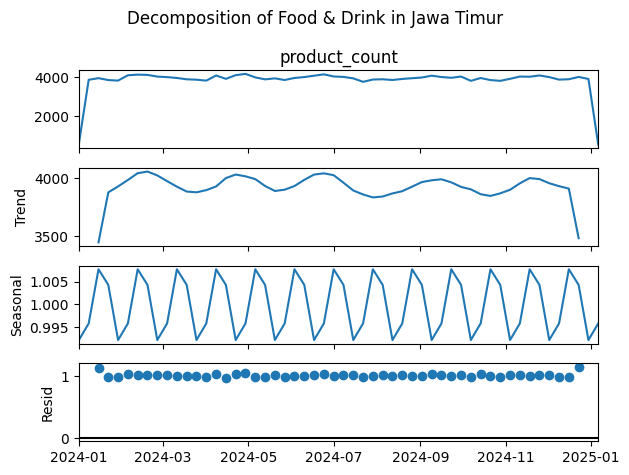

Processing Man Fashion...


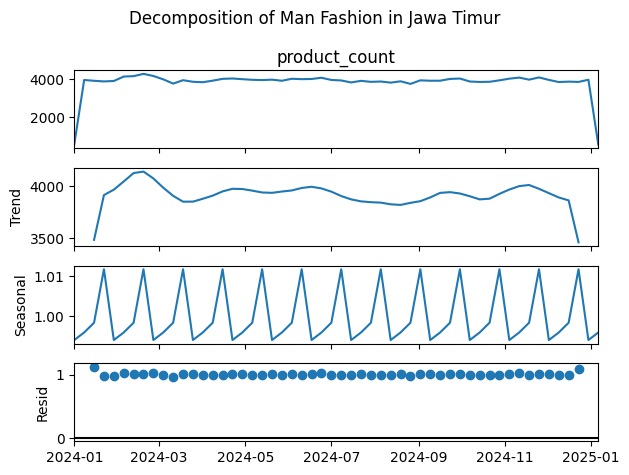

Processing Ride Hailing...


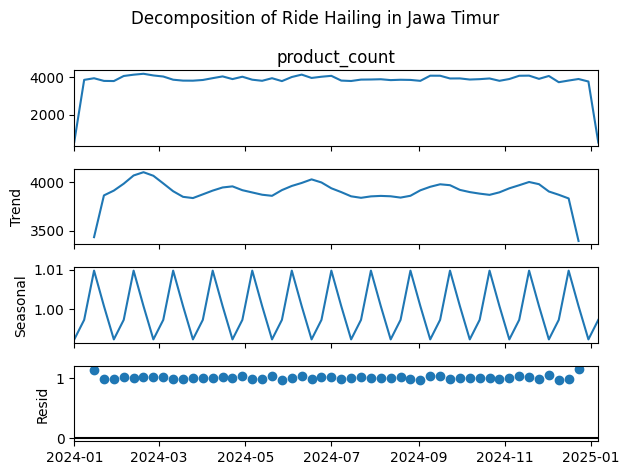

In [ ]:
# Membuat dataset untuk masing-masing kategori produk
datasets_jatim = {
    'Food & Drink': fooddrink_jatim,
    'Man Fashion': manfashion_jatim,
    'Ride Hailing': ridehailing_jatim
}

# Menerapkan dekomposisi pada setiap dataset
for product, data in datasets_jatim.items():
    print(f"Processing {product}...")

    # Ubah kolom tanggal transaksi ke dalam format datetime
    data['transaction_date'] = pd.to_datetime(data['transaction_date'])

    # Tetapkan kolom 'transaction_date' sebagai indeks
    data.set_index('transaction_date', inplace=True)

    # Pastikan tidak ada nilai yang hilang dalam kolom 'product_count'
    if data['product_count'].isnull().any():
        print(f"Warning: Dataset for {product} contains missing values in 'product_count'. Please handle missing values before proceeding.")
        continue

    # Decompose the differenced data
    decomposition_jatim = seasonal_decompose(data['product_count'], model='multiplicative', period=4)

    # Tambahkan kolom nilai residu ke dataset
    data['residual'] = decomposition_jatim.resid

    # Plot the decomposition
    fig = decomposition_jatim.plot()
    fig.suptitle(f'Decomposition of {product} in Jawa Timur')
    fig.tight_layout()
    plt.show()

    # Perbarui objek dekomposisi untuk setiap produk
    if product == 'Food & Drink':
        decomposition_fooddrink_jatim = decomposition_jatim
    elif product == 'Man Fashion':
        decomposition_manfashion_jatim = decomposition_jatim
    elif product == 'Ride Hailing':
        decomposition_ridehailing_jatim = decomposition_jatim


### 2. Cek Decomposition Data pada 3 dataset berdasarkan produk dalam provinsi Sumatera Utara

Processing Food & Drink...


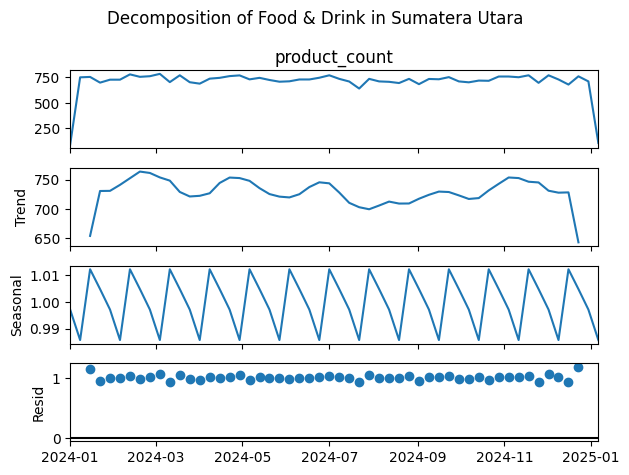

Processing Ride Hailing...


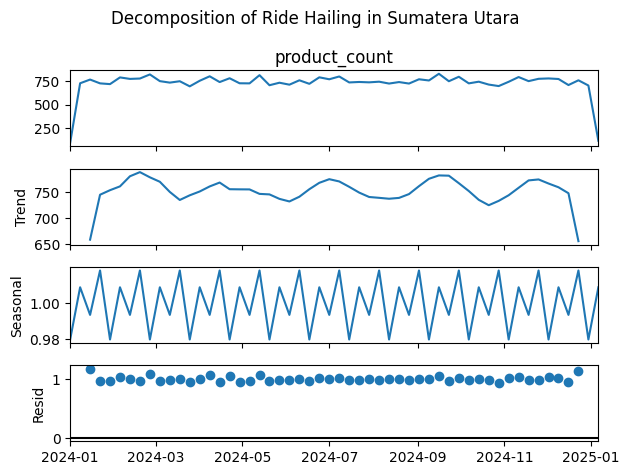

Processing Woman Fashion...


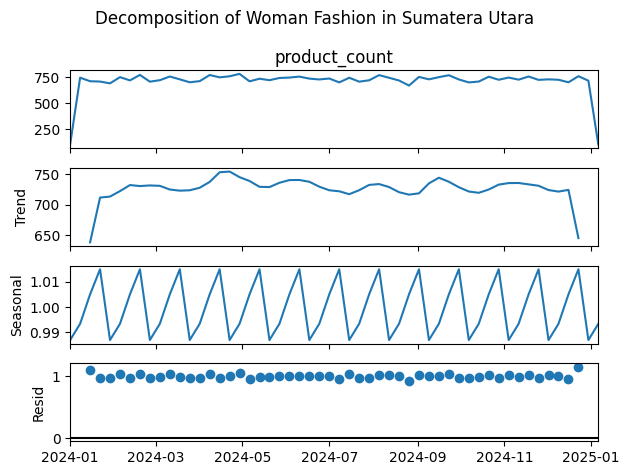

In [ ]:
# Membuat dataset untuk masing-masing kategori produk
datasets_sumut = {
    'Food & Drink': fooddrink_sumut,
    'Ride Hailing': ridehailing_sumut,
    'Woman Fashion': womanfashion_sumut
}

# Menerapkan dekomposisi pada setiap dataset
for product, data in datasets_sumut.items():
    print(f"Processing {product}...")

    # Ubah kolom tanggal transaksi ke dalam format datetime
    data['transaction_date'] = pd.to_datetime(data['transaction_date'])

    # Tetapkan kolom 'transaction_date' sebagai indeks
    data.set_index('transaction_date', inplace=True)

    # Pastikan tidak ada nilai yang hilang dalam kolom 'product_count'
    if data['product_count'].isnull().any():
        print(f"Warning: Dataset for {product} contains missing values in 'product_count'. Please handle missing values before proceeding.")
        continue

    # Decompose the differenced data
    decomposition_sumut = seasonal_decompose(data['product_count'], model='multiplicative', period=4)

    # Tambahkan kolom nilai residu ke dataset
    data['residual'] = decomposition_sumut.resid

    # Plot the decomposition
    fig = decomposition_sumut.plot()
    fig.suptitle(f'Decomposition of {product} in Sumatera Utara')
    fig.tight_layout()
    plt.show()

    # Perbarui objek dekomposisi untuk setiap produk
    if product == 'Food & Drink':
        decomposition_fooddrink_sumut = decomposition_sumut
    elif product == 'Ride Hailing':
        decomposition_ridehailing_sumut = decomposition_sumut
    elif product == 'Woman Fashion':
        decomposition_womanfashion_sumut = decomposition_sumut


### 3. Cek Decomposition Data pada 3 dataset berdasarkan produk dalam provinsi Sumatera Barat

Processing Elektronik...


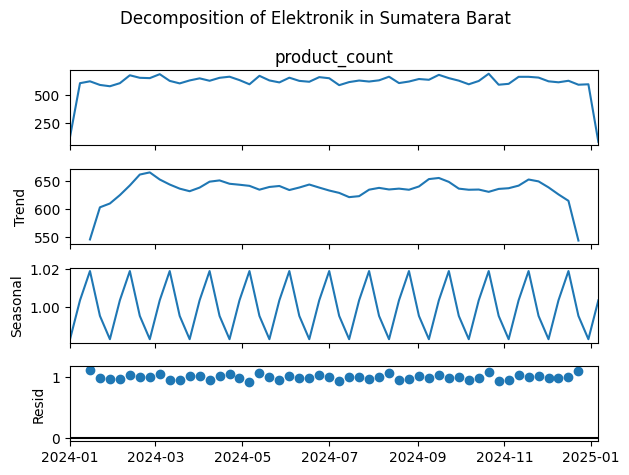

Processing Keperluan Rumah Tangga...


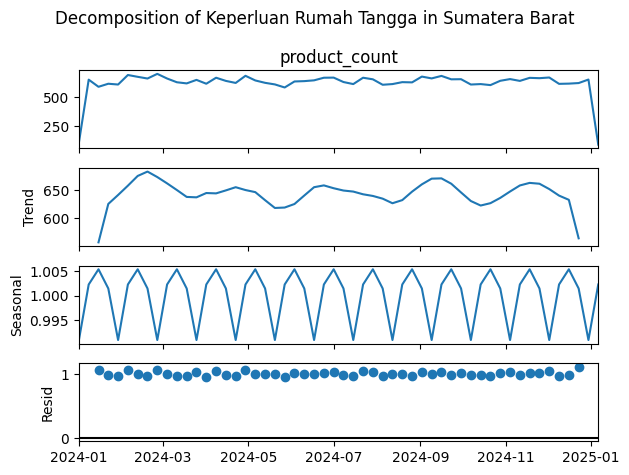

Processing Woman Fashion...


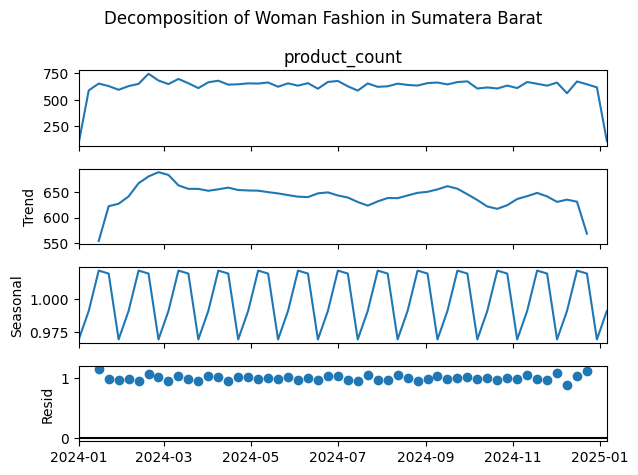

In [ ]:
# Membuat dataset untuk masing-masing kategori produk
datasets_sumbar = {
    'Elektronik': elektronik_sumbar,
    'Keperluan Rumah Tangga': keperluanRT_sumbar,
    'Woman Fashion': womanfashion_sumbar
}

# Menerapkan dekomposisi pada setiap dataset
for product, data in datasets_sumbar.items():
    print(f"Processing {product}...")

    # Ubah kolom tanggal transaksi ke dalam format datetime
    data['transaction_date'] = pd.to_datetime(data['transaction_date'])

    # Tetapkan kolom 'transaction_date' sebagai indeks
    data.set_index('transaction_date', inplace=True)

    # Pastikan tidak ada nilai yang hilang dalam kolom 'product_count'
    if data['product_count'].isnull().any():
        print(f"Warning: Dataset for {product} contains missing values in 'product_count'. Please handle missing values before proceeding.")
        continue

    # Decompose the differenced data
    decomposition_sumbar = seasonal_decompose(data['product_count'], model='multiplicative', period=4)

    # Tambahkan kolom nilai residu ke dataset
    data['residual'] = decomposition_sumbar.resid

    # Plot the decomposition
    fig = decomposition_sumbar.plot()
    fig.suptitle(f'Decomposition of {product} in Sumatera Barat')
    fig.tight_layout()
    plt.show()

    # Perbarui objek dekomposisi untuk setiap produk
    if product == 'Elektronik':
        decomposition_elektro_sumbar = decomposition_sumbar
    elif product == 'Keperluan Rumah Tangga':
        decomposition_krt_sumbar = decomposition_sumbar
    elif product == 'Woman Fashion':
        decomposition_wf_sumbar = decomposition_sumbar



### 4. Cek Decomposition Data pada 3 dataset berdasarkan produk dalam provinsi Maluku

Processing Keperluan Rumah Tangga...


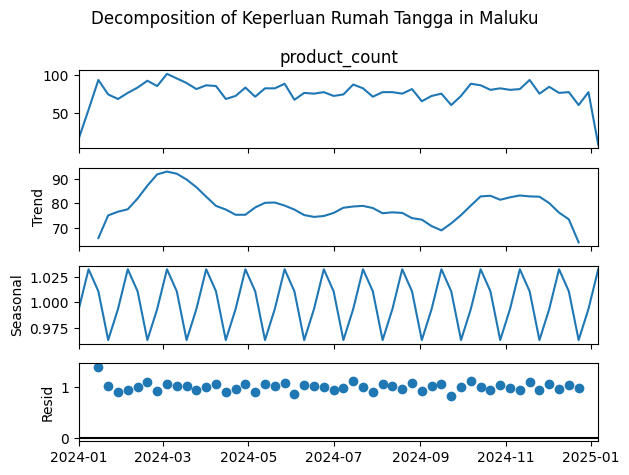

Processing Otomotif...


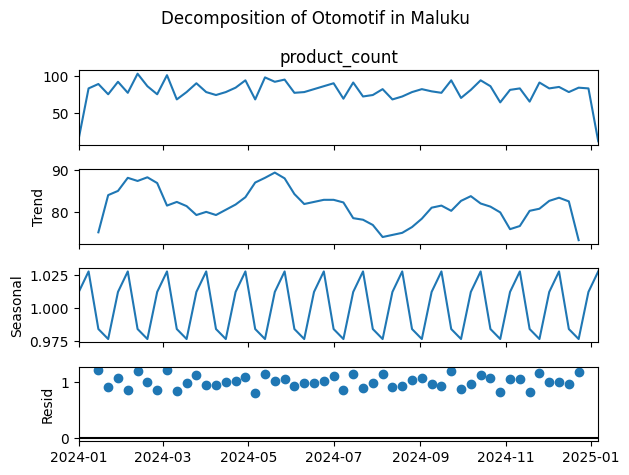

Processing Woman Fashion...


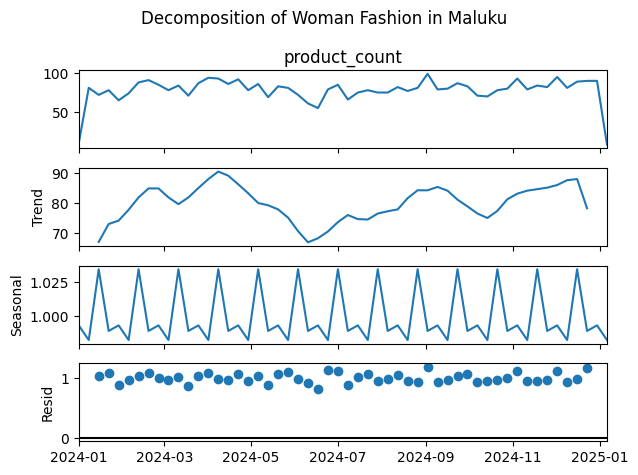

In [ ]:
# Membuat dataset untuk masing-masing kategori produk
datasets_maluku = {
    'Keperluan Rumah Tangga': keperluanRT_maluku,
    'Otomotif': otomotif_maluku,
    'Woman Fashion': womanfashion_maluku
}

# Menerapkan dekomposisi pada setiap dataset
for product, data in datasets_maluku.items():
    print(f"Processing {product}...")

    # Ubah kolom tanggal transaksi ke dalam format datetime
    data['transaction_date'] = pd.to_datetime(data['transaction_date'])

    # Tetapkan kolom 'transaction_date' sebagai indeks
    data.set_index('transaction_date', inplace=True)

    # Pastikan tidak ada nilai yang hilang dalam kolom 'product_count'
    if data['product_count'].isnull().any():
        print(f"Warning: Dataset for {product} contains missing values in 'product_count'. Please handle missing values before proceeding.")
        continue

    # Decompose the differenced data
    decomposition_maluku = seasonal_decompose(data['product_count'], model='multiplicative', period=4)

    # Tambahkan kolom nilai residu ke dataset
    data['residual'] = decomposition_maluku.resid

    # Plot the decomposition
    fig = decomposition_maluku.plot()
    fig.suptitle(f'Decomposition of {product} in Maluku')
    fig.tight_layout()
    plt.show()

    # Perbarui objek dekomposisi untuk setiap produk
    if product == 'Keperluan Rumah Tangga':
        decomposition_krt_maluku = decomposition_maluku
    elif product == 'Otomotif':
        decomposition_otomotif_maluku = decomposition_maluku
    elif product == 'Woman Fashion':
        decomposition_wf_maluku = decomposition_maluku

#**Check Stationarity Data**

### 1. Cek Stationarity Data pada 3 dataset berdasarkan produk dalam provinsi Jawa Timur

In [ ]:
# Loop through each dataset
for product, data in datasets_jatim.items():
    print(f"Processing {product}...")

    # Drop missing values in 'residu'
    data.dropna(subset=['residual'], inplace=True)

    # Melakukan ADF Test pada product_count
    if not data['residual'].isnull().values.any():  # Pastikan tidak ada NaN
        result = adfuller(data['residual'])
        print(f'ADF Statistic for {product}: {result[0]}')
        print(f'p-value for {product}: {result[1]}')
        print('Critical Values:')
        for key, value in result[4].items():
            print(f'\t{key}: {value:.3f}')

Processing Food & Drink...
ADF Statistic for Food & Drink: -7.094386118729595
p-value for Food & Drink: 4.3271091749441715e-10
Critical Values:
	1%: -3.575
	5%: -2.924
	10%: -2.600
Processing Man Fashion...
ADF Statistic for Man Fashion: -5.847687412745688
p-value for Man Fashion: 3.650866252598557e-07
Critical Values:
	1%: -3.575
	5%: -2.924
	10%: -2.600
Processing Ride Hailing...
ADF Statistic for Ride Hailing: -4.005975162323043
p-value for Ride Hailing: 0.001379544707249435
Critical Values:
	1%: -3.581
	5%: -2.927
	10%: -2.602


In [ ]:
# Loop through each dataset
for product, data in datasets_jatim.items():
    print(f"Processing {product}...")

    print(data.head())

Processing Food & Drink...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                 3925   343011100.0  1.129955
2024-01-22                 3827   320843400.0  0.982786
2024-01-29                 3801   315374400.0  0.975042
2024-02-05                 4072   342055900.0  1.026258
2024-02-12                 4106   352057000.0  1.007876
Processing Man Fashion...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                 3893   396357600.0  1.119973
2024-01-22                 3860   405731600.0  0.974496
2024-01-29                 3883   403515900.0  0.984718
2024-02-05                 4112   430256100.0  1.020448
2024-02-12                 4134   432174900.0  1.003208
Processing Ride Hailing...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15              

### 2. Cek Stationarity Data pada 3 dataset berdasarkan produk dalam provinsi Sumatera Utara

In [ ]:
# Loop through each dataset
for product, data in datasets_sumut.items():
    print(f"Processing {product}...")

    # Drop missing values in 'residu'
    data.dropna(subset=['residual'], inplace=True)

    # Melakukan ADF Test pada product_count
    if not data['residual'].isnull().values.any():  # Pastikan tidak ada NaN
        result = adfuller(data['residual'])
        print(f'ADF Statistic for {product}: {result[0]}')
        print(f'p-value for {product}: {result[1]}')
        print('Critical Values:')
        for key, value in result[4].items():
            print(f'\t{key}: {value:.3f}')

Processing Food & Drink...
ADF Statistic for Food & Drink: -4.8760782141953465
p-value for Food & Drink: 3.8812798141645664e-05
Critical Values:
	1%: -3.585
	5%: -2.928
	10%: -2.602
Processing Ride Hailing...
ADF Statistic for Ride Hailing: -8.961744857117296
p-value for Ride Hailing: 8.189166844190796e-15
Critical Values:
	1%: -3.575
	5%: -2.924
	10%: -2.600
Processing Woman Fashion...
ADF Statistic for Woman Fashion: -5.482289785160029
p-value for Woman Fashion: 2.270127093439826e-06
Critical Values:
	1%: -3.589
	5%: -2.930
	10%: -2.603


In [ ]:
# Loop through each dataset
for product, data in datasets_sumut.items():
    print(f"Processing {product}...")

    print(data.head())

Processing Food & Drink...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                  755    61856400.0  1.141251
2024-01-22                  699    58548400.0  0.952407
2024-01-29                  728    70711800.0  0.999264
2024-02-05                  728    58779700.0  0.996911
2024-02-12                  780    74553300.0  1.024265
Processing Ride Hailing...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                  769    96927700.0  1.177080
2024-01-22                  728    94246500.0  0.960695
2024-01-29                  720    86874200.0  0.975692
2024-02-05                  792    95731600.0  1.032427
2024-02-12                  776    97802400.0  1.001441
Processing Woman Fashion...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15            

### 3. Cek Stationarity Data pada 3 dataset berdasarkan produk dalam provinsi Sumatera Barat

In [ ]:
# Loop through each dataset
for product, data in datasets_sumbar.items():
    print(f"Processing {product}...")

    # Drop missing values in 'residu'
    data.dropna(subset=['residual'], inplace=True)

    # Melakukan ADF Test pada residual
    result = adfuller(data['residual'])
    print(f'ADF Statistic for {product}: {result[0]}')
    print(f'p-value for {product}: {result[1]}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.3f}')


Processing Elektronik...
ADF Statistic for Elektronik: -5.479909847252781
p-value for Elektronik: 2.2966935778330635e-06
Critical Values:
	1%: -3.581
	5%: -2.927
	10%: -2.602
Processing Keperluan Rumah Tangga...
ADF Statistic for Keperluan Rumah Tangga: -8.973567041040189
p-value for Keperluan Rumah Tangga: 7.638074453598966e-15
Critical Values:
	1%: -3.575
	5%: -2.924
	10%: -2.600
Processing Woman Fashion...
ADF Statistic for Woman Fashion: -10.055489342435166
p-value for Woman Fashion: 1.3766318774046536e-17
Critical Values:
	1%: -3.575
	5%: -2.924
	10%: -2.600


In [ ]:
# Loop through each dataset
for product, data in datasets_sumbar.items():
    print(f"Processing {product}...")

    print(data.head())

Processing Elektronik...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                  627    39190200.0  1.127727
2024-01-22                  594    37597600.0  0.989569
2024-01-29                  582    35698600.0  0.970798
2024-02-05                  610    36154700.0  0.972527
2024-02-12                  682    38772100.0  1.041699
Processing Keperluan Rumah Tangga...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                  593    48530800.0  1.059838
2024-01-22                  620    55572800.0  0.989561
2024-01-29                  613    49857100.0  0.964045
2024-02-05                  697    57523500.0  1.056053
2024-02-12                  681    54812400.0  1.001960
Processing Woman Fashion...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15    

### 4. Cek Stationarity Data pada 3 dataset berdasarkan produk dalam provinsi Maluku

In [ ]:
# Loop through each dataset
for product, data in datasets_maluku.items():
    print(f"Processing {product}...")

    # Drop missing values in 'residu'
    data.dropna(subset=['residual'], inplace=True)

    # Melakukan ADF Test pada residual
    result = adfuller(data['residual'])
    print(f'ADF Statistic for {product}: {result[0]}')
    print(f'p-value for {product}: {result[1]}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.3f}')


Processing Keperluan Rumah Tangga...
ADF Statistic for Keperluan Rumah Tangga: -8.171901876944903
p-value for Keperluan Rumah Tangga: 8.577938706493967e-13
Critical Values:
	1%: -3.578
	5%: -2.925
	10%: -2.601
Processing Otomotif...
ADF Statistic for Otomotif: -9.121489523637583
p-value for Otomotif: 3.1962905453690027e-15
Critical Values:
	1%: -3.578
	5%: -2.925
	10%: -2.601
Processing Woman Fashion...
ADF Statistic for Woman Fashion: -5.8960330678444555
p-value for Woman Fashion: 2.850062846869417e-07
Critical Values:
	1%: -3.581
	5%: -2.927
	10%: -2.602


In [ ]:
# Loop through each dataset
for product, data in datasets_maluku.items():
    print(f"Processing {product}...")

    print(data.head())

Processing Keperluan Rumah Tangga...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                   93     6269900.0  1.399144
2024-01-22                   74     5029600.0  1.024667
2024-01-29                   68     4590600.0  0.894725
2024-02-05                   76     3818400.0  0.949621
2024-02-12                   83     3860600.0  1.002772
Processing Otomotif...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15                   89     9618400.0  1.203871
2024-01-22                   75     5901400.0  0.914302
2024-01-29                   92    12281400.0  1.069538
2024-02-05                   77     6049700.0  0.850452
2024-02-12                  103     9412000.0  1.197911
Processing Woman Fashion...
                  product_count  total_amount  residual
transaction_date                                       
2024-01-15      

#**Using Auto_Arima to chosse model and parameter**

In [ ]:
!pip install pmdarima
import pandas as pd
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from pmdarima import auto_arima
import matplotlib.pyplot as plt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 7.8 MB/s eta 0:00:00


### 1. Auto_Arima untuk 3 Dataset berdasarkan product dalam provinsi Jawa Timur

In [ ]:
import pmdarima as pm

# Loop through each dataset
for product, data in datasets_jatim.items():

    # Menerapkan auto_arima hanya untuk 'Food & Drink'
    if product == 'Food & Drink':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Food & Drink...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[4] intercept   : AIC=-178.154, Time=1.99 sec
 ARIMA(0,0,0)(0,1,0)[4] intercept   : AIC=-172.417, Time=0.12 sec
 ARIMA(1,0,0)(1,1,0)[4] intercept   : AIC=-174.740, Time=0.86 sec
 ARIMA(0,0,1)(0,1,1)[4] intercept   : AIC=-180.013, Time=1.33 sec
 ARIMA(0,0,0)(0,1,0)[4]             : AIC=-174.417, Time=0.08 sec
 ARIMA(0,0,1)(0,1,0)[4] intercept   : AIC=-178.205, Time=0.23 sec
 ARIMA(0,0,1)(1,1,1)[4] intercept   : AIC=-176.108, Time=0.43 sec
 ARIMA(0,0,1)(0,1,2)[4] intercept   : AIC=-173.175, Time=2.00 sec
 ARIMA(0,0,1)(1,1,0)[4] intercept   : AIC=-178.683, Time=0.39 sec
 ARIMA(0,0,1)(1,1,2)[4] intercept   : AIC=inf, Time=2.29 sec
 ARIMA(0,0,0)(0,1,1)[4] intercept   : AIC=-175.049, Time=0.32 sec
 ARIMA(1,0,1)(0,1,1)[4] intercept   : AIC=-176.991, Time=0.63 sec
 ARIMA(0,0,2)(0,1,1)[4] intercept   : AIC=-178.606, Time=1.42 sec
 ARIMA(1,0,0)(0,1,1)[4] intercept   : AIC=-175.819, Time=1.23 sec
 ARIMA(1,0,

In [ ]:
# Loop through each dataset
for product, data in datasets_jatim.items():

    # Menerapkan auto_arima hanya untuk 'Man Fashion'
    if product == 'Man Fashion':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Man Fashion...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-221.402, Time=2.58 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-223.061, Time=0.11 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.67 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=-226.740, Time=0.74 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.335, Time=0.07 sec
 ARIMA(0,0,1)(0,0,0)[4] intercept   : AIC=-228.393, Time=0.44 sec
 ARIMA(0,0,1)(1,0,0)[4] intercept   : AIC=-189.410, Time=1.20 sec
 ARIMA(0,0,1)(1,0,1)[4] intercept   : AIC=-224.134, Time=1.77 sec
 ARIMA(1,0,1)(0,0,0)[4] intercept   : AIC=-219.321, Time=0.57 sec
 ARIMA(0,0,2)(0,0,0)[4] intercept   : AIC=-226.559, Time=0.60 sec
 ARIMA(1,0,0)(0,0,0)[4] intercept   : AIC=-224.051, Time=0.24 sec
 ARIMA(1,0,2)(0,0,0)[4] intercept   : AIC=-225.234, Time=1.67 sec
 ARIMA(0,0,1)(0,0,0)[4]             : AIC=inf, Time=0.21 sec

Best model:  ARIMA(0,0,1)(0,0,0)[4] intercept
Total fit time: 10.993 seconds
      

In [ ]:
# Loop through each dataset
for product, data in datasets_jatim.items():

    # Menerapkan auto_arima hanya untuk 'Ride Hailing'
    if product == 'Ride Hailing':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Ride Hailing...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-208.220, Time=4.09 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-193.524, Time=0.14 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=1.02 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=-208.957, Time=0.86 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.453, Time=0.04 sec
 ARIMA(0,0,1)(0,0,0)[4] intercept   : AIC=inf, Time=0.86 sec
 ARIMA(0,0,1)(1,0,1)[4] intercept   : AIC=-203.140, Time=2.15 sec
 ARIMA(0,0,1)(0,0,2)[4] intercept   : AIC=-209.464, Time=1.43 sec
 ARIMA(0,0,1)(1,0,2)[4] intercept   : AIC=inf, Time=2.74 sec
 ARIMA(0,0,0)(0,0,2)[4] intercept   : AIC=-195.805, Time=0.47 sec
 ARIMA(1,0,1)(0,0,2)[4] intercept   : AIC=-195.655, Time=2.20 sec
 ARIMA(0,0,2)(0,0,2)[4] intercept   : AIC=-208.270, Time=0.99 sec
 ARIMA(1,0,0)(0,0,2)[4] intercept   : AIC=-198.226, Time=1.29 sec
 ARIMA(1,0,2)(0,0,2)[4] intercept   : AIC=inf, Time=3.98 sec
 ARIMA(0,0,1)(0,0,2)[4]    

### 2. Auto_Arima untuk 3 Dataset berdasarkan product dalam provinsi Sumatera Utara

In [ ]:
# Loop through each dataset
for product, data in datasets_sumut.items():

    # Menerapkan auto_arima hanya untuk 'Food & Drink'
    if product == 'Food & Drink':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Food & Drink...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-188.641, Time=3.14 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-164.990, Time=0.15 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=-184.330, Time=1.12 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=3.26 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.485, Time=0.08 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=-191.754, Time=3.86 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=-185.150, Time=1.77 sec
 ARIMA(2,0,2)(0,0,2)[4] intercept   : AIC=-183.700, Time=3.56 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=-189.705, Time=2.65 sec
 ARIMA(2,0,2)(1,0,2)[4] intercept   : AIC=-111.124, Time=2.57 sec
 ARIMA(1,0,2)(0,0,1)[4] intercept   : AIC=inf, Time=0.94 sec
 ARIMA(2,0,1)(0,0,1)[4] intercept   : AIC=-197.690, Time=2.28 sec
 ARIMA(2,0,1)(0,0,0)[4] intercept   : AIC=-186.868, Time=0.32 sec
 ARIMA(2,0,1)(1,0,1)[4] intercept   : AIC=-194.028, Time=2.20 sec
 ARIMA(2,0,1)(0,0

In [ ]:
# Loop through each dataset
for product, data in datasets_sumut.items():

    # Menerapkan auto_arima hanya untuk 'Ride Hailing'
    if product == 'Ride Hailing':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Ride Hailing...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-174.880, Time=0.55 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-164.391, Time=0.05 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.33 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.82 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.548, Time=0.04 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=-177.558, Time=0.93 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=-178.438, Time=0.78 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=-135.758, Time=1.17 sec
 ARIMA(1,0,2)(0,0,0)[4] intercept   : AIC=-179.397, Time=0.97 sec
 ARIMA(1,0,2)(1,0,0)[4] intercept   : AIC=inf, Time=1.56 sec
 ARIMA(1,0,2)(0,0,1)[4] intercept   : AIC=-181.773, Time=0.35 sec
 ARIMA(1,0,2)(1,0,1)[4] intercept   : AIC=-177.201, Time=0.82 sec
 ARIMA(1,0,2)(0,0,2)[4] intercept   : AIC=-179.625, Time=0.54 sec
 ARIMA(1,0,2)(1,0,2)[4] intercept   : AIC=-174.803, Time=2.28 sec
 ARIMA(0,0,2)(0,0,1)[4

In [ ]:
# Loop through each dataset
for product, data in datasets_sumut.items():

    # Menerapkan auto_arima hanya untuk 'Woman Fashion'
    if product == 'Woman Fashion':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Woman Fashion...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-189.343, Time=2.03 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-182.568, Time=0.11 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.50 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.80 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.399, Time=0.02 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=inf, Time=3.14 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=-144.012, Time=0.95 sec
 ARIMA(2,0,2)(2,0,1)[4] intercept   : AIC=inf, Time=1.01 sec
 ARIMA(2,0,2)(1,0,2)[4] intercept   : AIC=inf, Time=1.15 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=inf, Time=0.61 sec
 ARIMA(2,0,2)(0,0,2)[4] intercept   : AIC=inf, Time=1.69 sec
 ARIMA(2,0,2)(2,0,0)[4] intercept   : AIC=inf, Time=0.88 sec
 ARIMA(2,0,2)(2,0,2)[4] intercept   : AIC=inf, Time=1.19 sec
 ARIMA(1,0,2)(1,0,1)[4] intercept   : AIC=-194.589, Time=0.85 sec
 ARIMA(1,0,2)(0,0,1)[4] intercept   : AIC=-193.725,

### 3. Auto_Arima untuk 3 Dataset berdasarkan product dalam provinsi Sumatera Barat

In [ ]:
# Loop through each dataset
for product, data in datasets_sumbar.items():

    # Menerapkan auto_arima hanya untuk 'Elektronik'
    if product == 'Elektronik':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Elektronik...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-183.555, Time=1.17 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-171.206, Time=0.05 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.34 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.28 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.435, Time=0.02 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=-195.886, Time=0.44 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=-193.504, Time=0.41 sec
 ARIMA(2,0,2)(0,0,2)[4] intercept   : AIC=-197.538, Time=2.38 sec
 ARIMA(2,0,2)(1,0,2)[4] intercept   : AIC=-169.095, Time=2.93 sec
 ARIMA(1,0,2)(0,0,2)[4] intercept   : AIC=inf, Time=1.56 sec
 ARIMA(2,0,1)(0,0,2)[4] intercept   : AIC=inf, Time=0.44 sec
 ARIMA(3,0,2)(0,0,2)[4] intercept   : AIC=inf, Time=0.85 sec
 ARIMA(2,0,3)(0,0,2)[4] intercept   : AIC=-192.871, Time=0.80 sec
 ARIMA(1,0,1)(0,0,2)[4] intercept   : AIC=inf, Time=0.71 sec
 ARIMA(1,0,3)(0,0,2)[4] intercept   : A

In [ ]:
# Loop through each dataset
for product, data in datasets_sumbar.items():

    # Menerapkan auto_arima hanya untuk 'Keperluan Rumah Tangga'
    if product == 'Keperluan Rumah Tangga':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Keperluan Rumah Tangga...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-204.166, Time=0.73 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-194.444, Time=0.05 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.38 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=-208.809, Time=0.12 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.262, Time=0.02 sec
 ARIMA(0,0,1)(0,0,0)[4] intercept   : AIC=inf, Time=0.13 sec
 ARIMA(0,0,1)(1,0,1)[4] intercept   : AIC=-205.702, Time=0.17 sec
 ARIMA(0,0,1)(0,0,2)[4] intercept   : AIC=-207.221, Time=0.26 sec
 ARIMA(0,0,1)(1,0,0)[4] intercept   : AIC=inf, Time=0.47 sec
 ARIMA(0,0,1)(1,0,2)[4] intercept   : AIC=-199.079, Time=1.04 sec
 ARIMA(0,0,0)(0,0,1)[4] intercept   : AIC=-192.723, Time=0.05 sec
 ARIMA(1,0,1)(0,0,1)[4] intercept   : AIC=-188.723, Time=0.42 sec
 ARIMA(0,0,2)(0,0,1)[4] intercept   : AIC=-208.637, Time=0.66 sec
 ARIMA(1,0,0)(0,0,1)[4] intercept   : AIC=-196.186, Time=0.20 sec
 ARIMA(1,0,2

In [ ]:
# Loop through each dataset
for product, data in datasets_sumbar.items():

    # Menerapkan auto_arima hanya untuk 'Woman Fashion'
    if product == 'Woman Fashion':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Woman Fashion...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-181.809, Time=4.32 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-163.544, Time=0.05 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.29 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.23 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.528, Time=0.02 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=-186.654, Time=0.55 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=-189.959, Time=0.39 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=-108.542, Time=0.62 sec
 ARIMA(1,0,2)(0,0,0)[4] intercept   : AIC=-185.816, Time=0.58 sec
 ARIMA(2,0,1)(0,0,0)[4] intercept   : AIC=-183.586, Time=0.27 sec
 ARIMA(3,0,2)(0,0,0)[4] intercept   : AIC=-179.360, Time=0.40 sec
 ARIMA(2,0,3)(0,0,0)[4] intercept   : AIC=-186.519, Time=0.33 sec
 ARIMA(1,0,1)(0,0,0)[4] intercept   : AIC=-161.485, Time=0.26 sec
 ARIMA(1,0,3)(0,0,0)[4] intercept   : AIC=-186.682, Time=0.18 sec
 ARIMA(3,0,1)(0,

### 4. Auto_Arima untuk 3 Dataset berdasarkan product dalam provinsi Maluku

In [ ]:
# Loop through each dataset
for product, data in datasets_maluku.items():

    # Menerapkan auto_arima hanya untuk 'Keperluan Rumah Tangga'
    if product == 'Keperluan Rumah Tangga':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Keperluan Rumah Tangga...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=inf, Time=0.86 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-98.183, Time=0.04 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=-87.352, Time=0.31 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.27 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=145.001, Time=0.02 sec
 ARIMA(0,0,0)(1,0,0)[4] intercept   : AIC=-93.305, Time=0.29 sec
 ARIMA(0,0,0)(0,0,1)[4] intercept   : AIC=-96.412, Time=0.10 sec
 ARIMA(0,0,0)(1,0,1)[4] intercept   : AIC=inf, Time=0.33 sec
 ARIMA(1,0,0)(0,0,0)[4] intercept   : AIC=-99.728, Time=0.12 sec
 ARIMA(1,0,0)(0,0,1)[4] intercept   : AIC=-98.393, Time=0.20 sec
 ARIMA(1,0,0)(1,0,1)[4] intercept   : AIC=inf, Time=0.42 sec
 ARIMA(2,0,0)(0,0,0)[4] intercept   : AIC=-109.097, Time=0.22 sec
 ARIMA(2,0,0)(1,0,0)[4] intercept   : AIC=-87.216, Time=0.92 sec
 ARIMA(2,0,0)(0,0,1)[4] intercept   : AIC=-107.134, Time=0.56 sec
 ARIMA(2,0,0)(1,0,1)[4] 

In [ ]:
# Loop through each dataset
for product, data in datasets_maluku.items():

    # Menerapkan auto_arima hanya untuk 'Otomotif'
    if product == 'Otomotif':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Otomotif...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,1,1)[4] intercept   : AIC=inf, Time=0.53 sec
 ARIMA(0,0,0)(0,1,0)[4] intercept   : AIC=-34.365, Time=0.03 sec
 ARIMA(1,0,0)(1,1,0)[4] intercept   : AIC=-56.231, Time=0.11 sec
 ARIMA(0,0,1)(0,1,1)[4] intercept   : AIC=inf, Time=0.44 sec
 ARIMA(0,0,0)(0,1,0)[4]             : AIC=-36.359, Time=0.03 sec
 ARIMA(1,0,0)(0,1,0)[4] intercept   : AIC=-53.942, Time=0.09 sec
 ARIMA(1,0,0)(2,1,0)[4] intercept   : AIC=-59.356, Time=0.27 sec
 ARIMA(1,0,0)(2,1,1)[4] intercept   : AIC=inf, Time=0.56 sec
 ARIMA(1,0,0)(1,1,1)[4] intercept   : AIC=inf, Time=0.43 sec
 ARIMA(0,0,0)(2,1,0)[4] intercept   : AIC=-42.451, Time=0.13 sec
 ARIMA(2,0,0)(2,1,0)[4] intercept   : AIC=-79.126, Time=0.36 sec
 ARIMA(2,0,0)(1,1,0)[4] intercept   : AIC=-76.537, Time=0.32 sec
 ARIMA(2,0,0)(2,1,1)[4] intercept   : AIC=inf, Time=0.55 sec
 ARIMA(2,0,0)(1,1,1)[4] intercept   : AIC=inf, Time=0.59 sec
 ARIMA(3,0,0)(2,1,0)[4] intercept   : AIC=-82.62

In [ ]:
# Loop through each dataset
for product, data in datasets_maluku.items():

    # Menerapkan auto_arima hanya untuk 'Woman Fashion'
    if product == 'Woman Fashion':
        print(f"Processing {product}...")
        model = pm.auto_arima(data['residual'], seasonal=True, m=4, trace=True)

        # Tampilkan informasi tentang model terbaik yang ditemukan
        print(model.summary())

Processing Woman Fashion...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=-122.667, Time=0.59 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=-106.982, Time=0.04 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=inf, Time=0.28 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=inf, Time=0.32 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=144.501, Time=0.02 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=-127.229, Time=0.60 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=-130.203, Time=1.76 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=-53.484, Time=1.21 sec
 ARIMA(1,0,2)(0,0,0)[4] intercept   : AIC=inf, Time=0.64 sec
 ARIMA(2,0,1)(0,0,0)[4] intercept   : AIC=-108.910, Time=0.46 sec
 ARIMA(3,0,2)(0,0,0)[4] intercept   : AIC=-122.166, Time=1.10 sec
 ARIMA(2,0,3)(0,0,0)[4] intercept   : AIC=-129.387, Time=1.11 sec
 ARIMA(1,0,1)(0,0,0)[4] intercept   : AIC=inf, Time=0.22 sec
 ARIMA(1,0,3)(0,0,0)[4] intercept   : AIC=-129.542, Time=1.53 sec
 ARIMA(3,0,1)(0,0,0)[4] int

# **Modeling Dataset for TimeSeries**

###1. Modeling 3 dataset berdasarkan produk dalam Jawa Timur

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


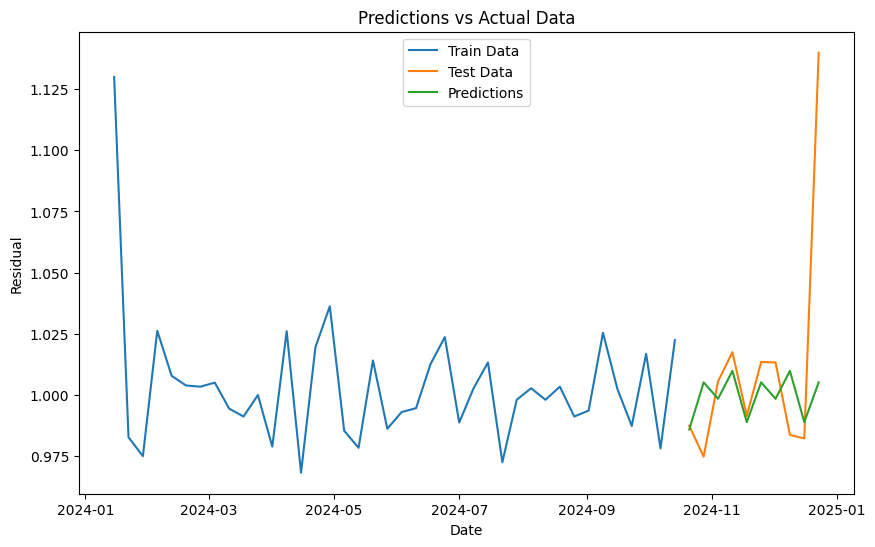

Root Mean Squared Error: 0.04492779118929626


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Food & Drink'
data_fooddrink = datasets_jatim['Food & Drink']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_fooddrink['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 1, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_fd = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_fd.index, predictions_fd, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_fd)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


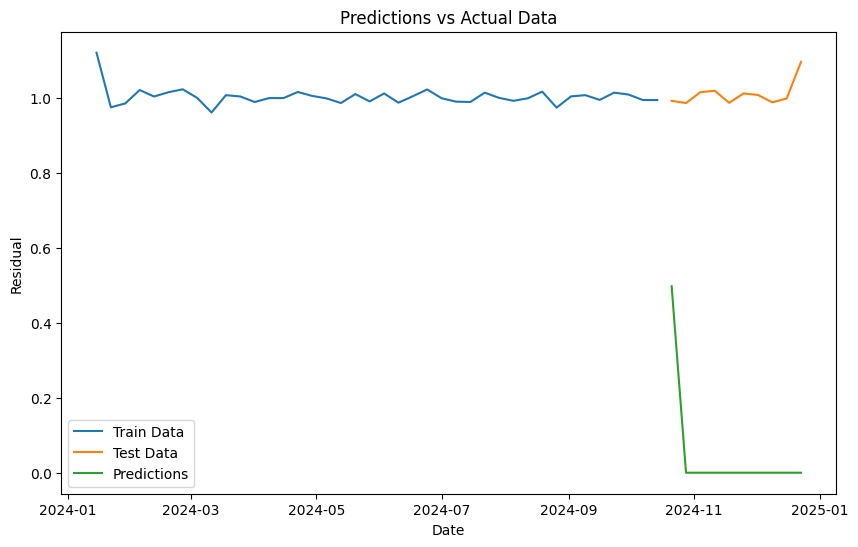

Root Mean Squared Error: 0.9729365233037673


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Man Fashion'
data_manfashion = datasets_jatim['Man Fashion']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_manfashion['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, 0, 0)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_mf = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_mf.index, predictions_mf, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_mf)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'


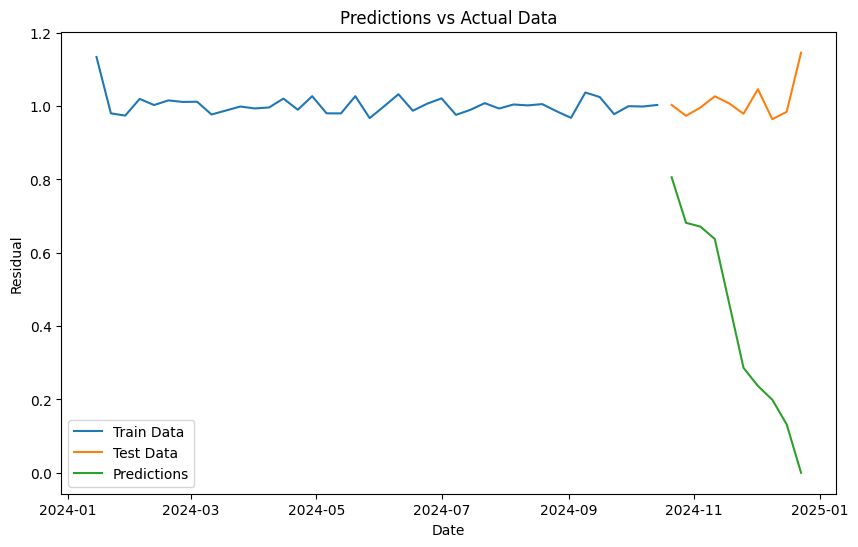

Root Mean Squared Error: 0.6663178440489901


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Ride Hailing'
data_ridehailing = datasets_jatim['Ride Hailing']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_ridehailing['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, [1,2], 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_rh = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_rh.index, predictions_rh, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_rh)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

###2. Modeling 3 dataset berdasarkan produk dalam Sumatera Utara

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


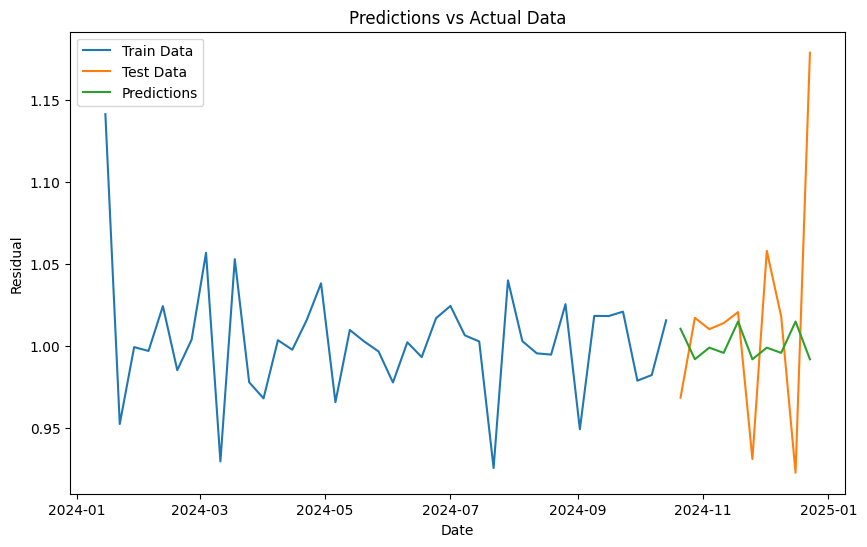

Root Mean Squared Error: 0.07346390402494055


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Food & Drink'
data_fooddrink = datasets_sumut['Food & Drink']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_fooddrink['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 1, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_fd = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_fd.index, predictions_fd, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_fd)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


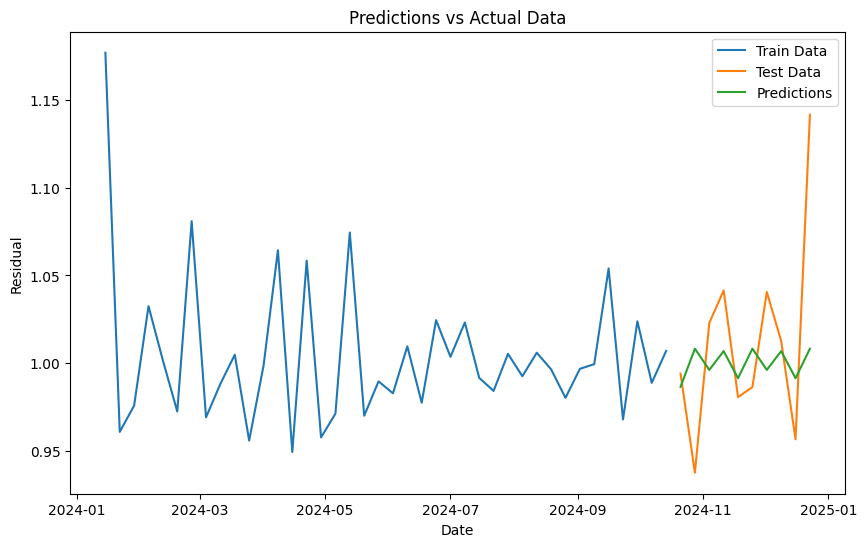

Root Mean Squared Error: 0.05352040310975506


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Ride Hailing'
data_ridehailing = datasets_sumut['Ride Hailing']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_ridehailing['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 1, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_fd = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_fd.index, predictions_fd, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_fd)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


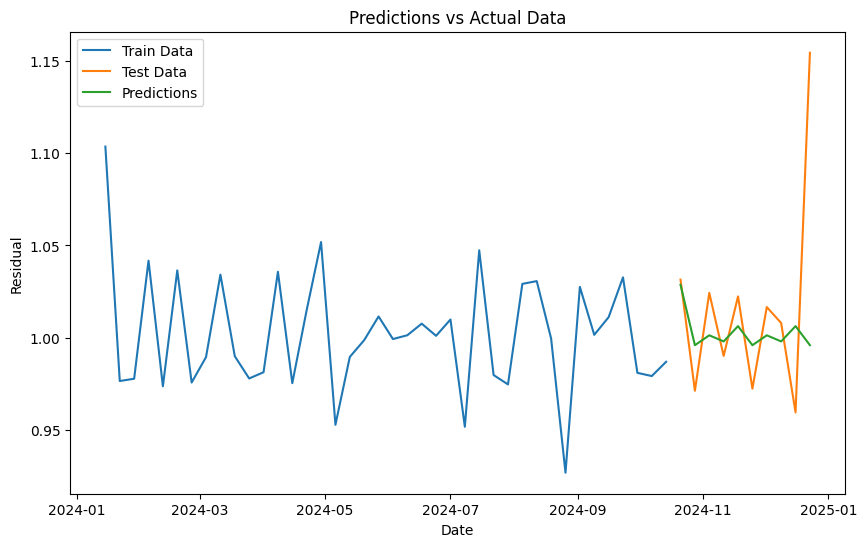

Root Mean Squared Error: 0.054482343491022746


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Woman Fashion'
data_womanfashion = datasets_sumut['Woman Fashion']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_womanfashion['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 1, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_fd = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_fd.index, predictions_fd, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_fd)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

###3. Modeling 3 dataset berdasarkan produk dalam Sumatera Barat

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertib

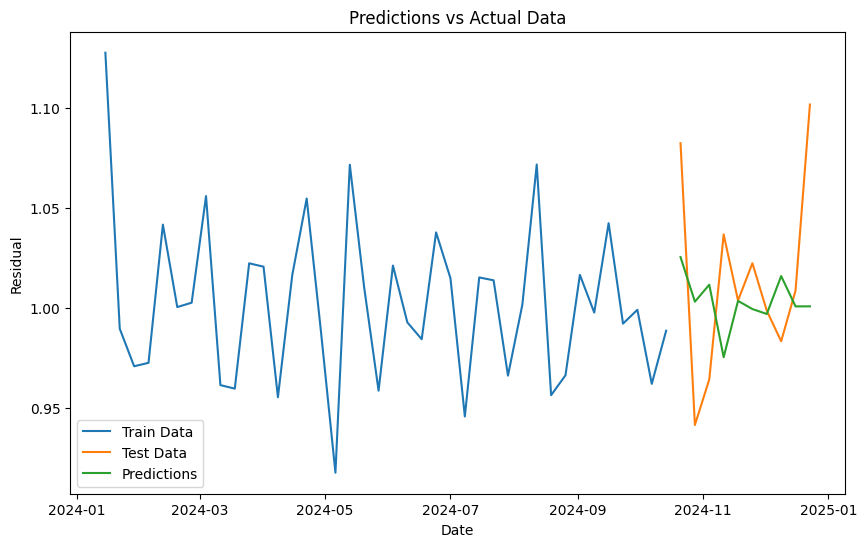

Root Mean Squared Error: 0.049944905406454305


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Elektronik'
data_elektro = datasets_sumbar['Elektronik']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_elektro['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (2, 0, 2)  # Orde ARIMA
seasonal_order = (0, 0, 2, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_e = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_e.index, predictions_e, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_e)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


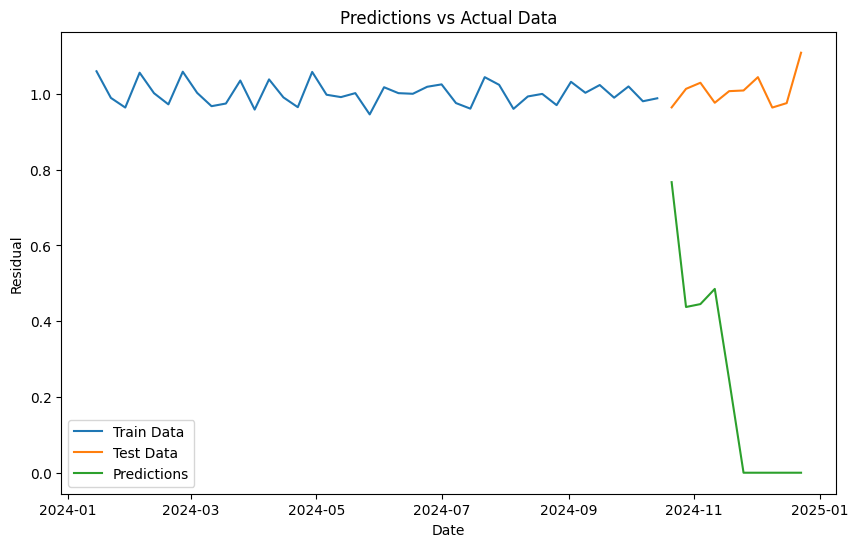

Root Mean Squared Error: 0.8218304782134338


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Elektronik'
data_krt = datasets_sumbar['Keperluan Rumah Tangga']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_krt['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_krt = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_krt.index, predictions_krt, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_krt)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


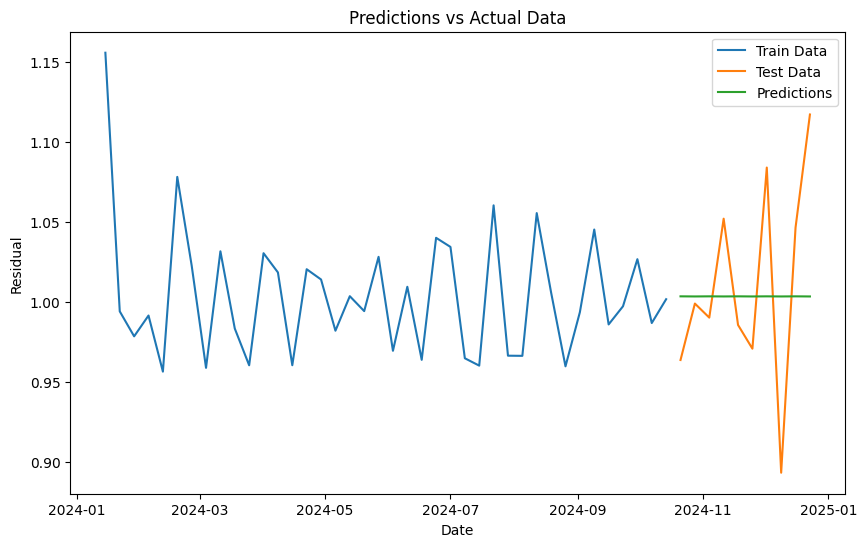

Root Mean Squared Error: 0.06244046581847841


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Elektronik'
data_wf = datasets_sumbar['Woman Fashion']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_wf['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (2, 0, 2)  # Orde ARIMA
seasonal_order = (0, 0, 0, 0)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_wf = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_wf.index, predictions_wf, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_wf)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

###4. Modeling 3 dataset berdasarkan produk dalam Maluku

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


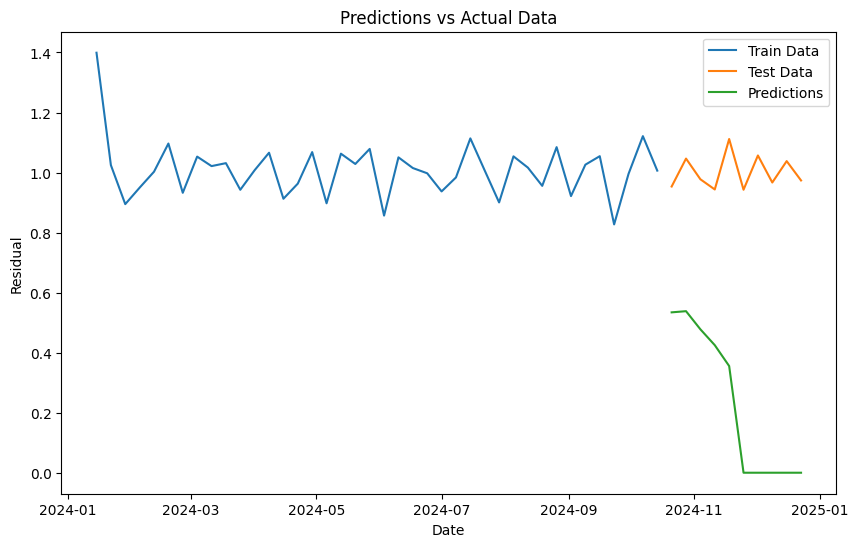

Root Mean Squared Error: 0.8056513890983819


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Keperluan Rumah Tangga'
data_krt = datasets_maluku['Keperluan Rumah Tangga']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_krt['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_krt = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_krt.index, predictions_krt, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()

# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_krt)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


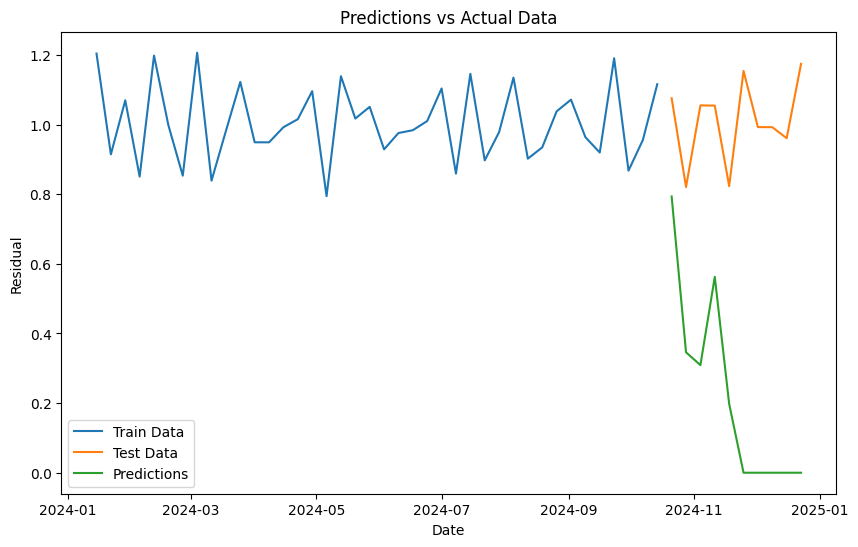

Root Mean Squared Error: 0.84248831501655


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Otomotif'
data_krt = datasets_maluku['Otomotif']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_krt['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_krt = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_krt.index, predictions_krt, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_krt)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)


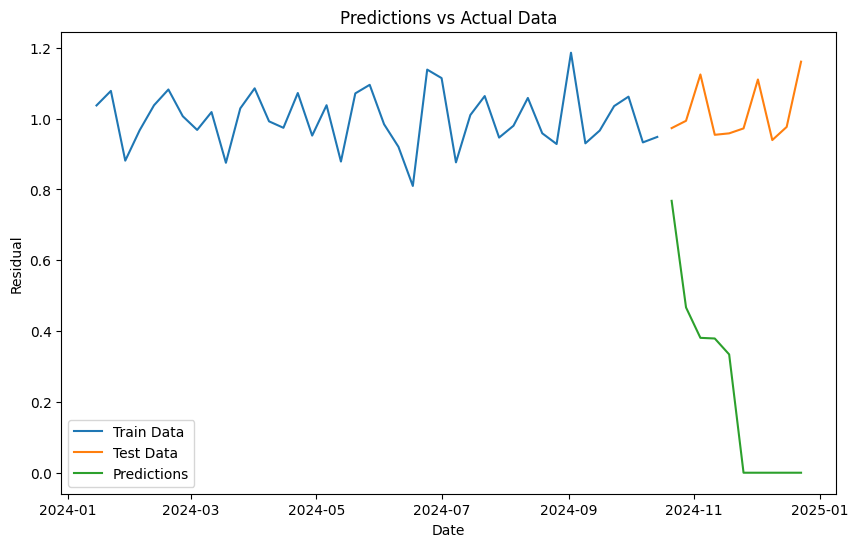

Root Mean Squared Error: 0.8338851873092533


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Ambil dataset untuk kategori 'Woman Fashion'
data_krt = datasets_maluku['Woman Fashion']

# Bagi dataset menjadi data pelatihan dan data uji
train_data, test_data = train_test_split(data_krt['residual'], test_size=0.2, shuffle=False)

# Set parameter model sesuai dengan hasil auto_arima
order = (0, 0, 1)  # Orde ARIMA
seasonal_order = (0, 0, 1, 4)  # Orde musiman

# Pelatihan model
model = sm.tsa.SARIMAX(train_data, order=order, seasonal_order=seasonal_order)
result = model.fit()

# Prediksi menggunakan data uji
predictions_krt = result.predict(start=test_data.index[0], end=test_data.index[-1])

# Visualisasi prediksi
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data, label='Train Data')
plt.plot(test_data.index, test_data, label='Test Data')
plt.plot(predictions_krt.index, predictions_krt, label='Predictions')
plt.title('Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.legend()
plt.show()


# Evaluasi kinerja model
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(test_data, predictions_krt)
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

#**Undo Stationarity To Testing Dataset**

### 1. Undo Stationarity 3 Dataset berdasarkan produk dalam Jawa Timur

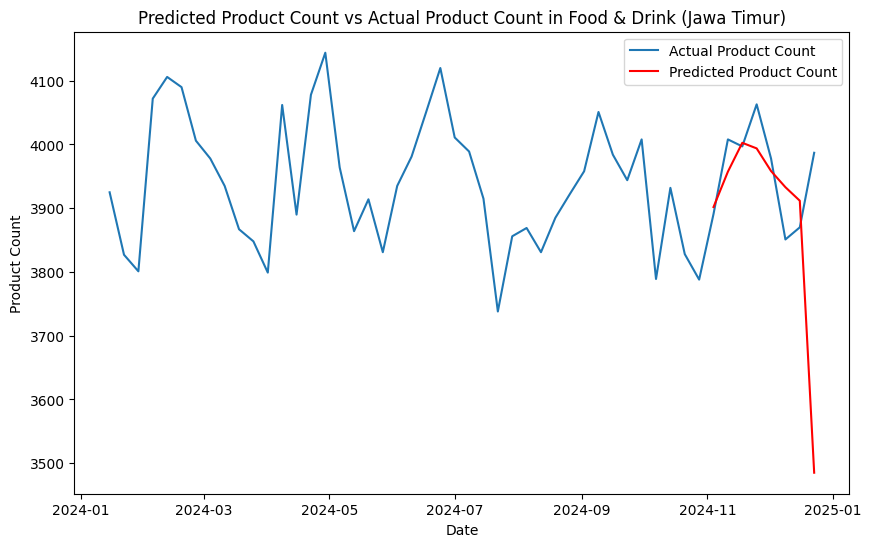

Root Mean Squared Error: 183.1488748057473


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Food & Drink'
if decomposition_fooddrink_jatim is not None:
    # Ambil dataset untuk kategori 'Food & Drink'
    data_fooddrink = datasets_jatim['Food & Drink']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_fooddrink_jatim.trend[-len(predictions_fd):]
    seasonal_component = decomposition_fooddrink_jatim.seasonal[-len(predictions_fd):]
    predictions_product_count = trend_component + seasonal_component + predictions_fd

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_fooddrink['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_fooddrink['product_count'].index, data_fooddrink['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Food & Drink (Jawa Timur)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Food & Drink' dataset.")

In [ ]:
import pandas as pd

if decomposition_fooddrink_jatim is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    jatim_fd_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(jatim_fd_pred.head())

else:
    print("Warning: No decomposition results found for 'Food & Drink' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                  3891                3901.868521
1 2024-11-11                  4008                3957.368832
2 2024-11-18                  3997                4002.638965
3 2024-11-25                  4063                3993.875204
4 2024-12-02                  3978                3958.368521


In [ ]:
# Simpan DataFrame ke dalam file CSV
jatim_fd_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/jatim_fd_pred.csv', index=False)

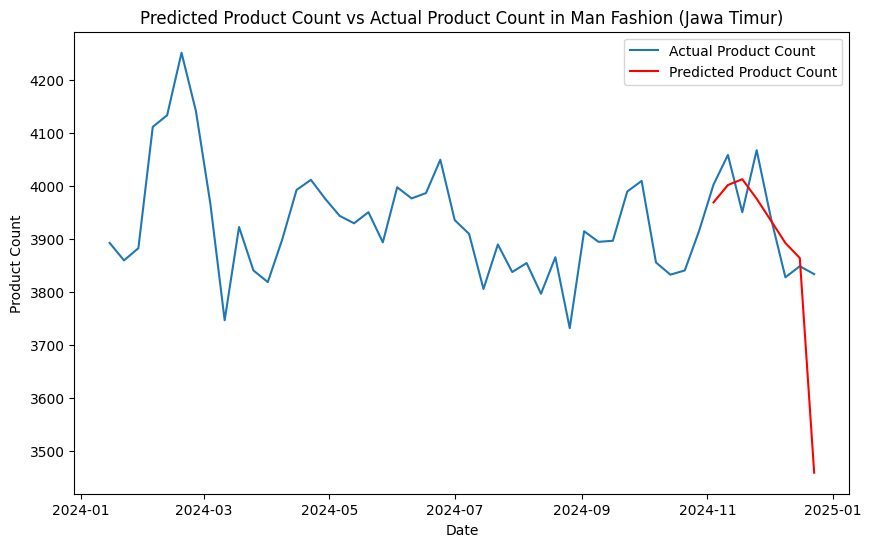

Root Mean Squared Error: 192.43307721708416


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Man Fashion'
if decomposition_manfashion_jatim is not None:
    # Ambil dataset untuk kategori 'Man Faashion'
    data_manfashion = datasets_jatim['Man Fashion']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_manfashion_jatim.trend[-len(predictions_mf):]
    seasonal_component = decomposition_manfashion_jatim.seasonal[-len(predictions_mf):]
    predictions_product_count = trend_component + seasonal_component + predictions_mf

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_fooddrink['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_manfashion['product_count'].index, data_manfashion['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Man Fashion (Jawa Timur)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Man Fashion' dataset.")

In [ ]:
import pandas as pd

if decomposition_manfashion_jatim is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    jatim_mf_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(jatim_mf_pred.head())

else:
    print("Warning: No decomposition results found for 'Man Fashion' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                  3891                3969.493985
1 2024-11-11                  4008                4002.245886
2 2024-11-18                  3997                4013.248341
3 2024-11-25                  4063                3976.386788
4 2024-12-02                  3978                3934.743985


In [ ]:
# Simpan DataFrame ke dalam file CSV
jatim_mf_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/jatim_mf_pred.csv', index=False)

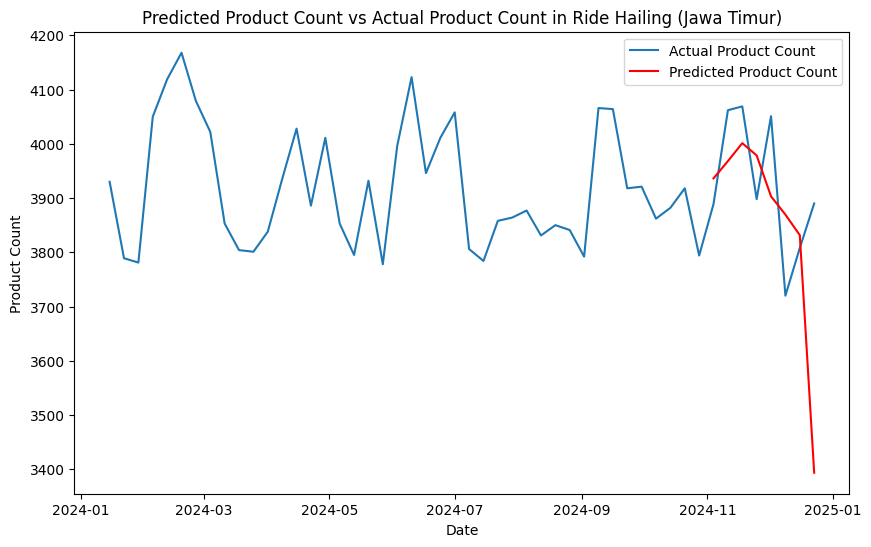

Root Mean Squared Error: 215.19298713893204


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Ride Hailing'
if decomposition_ridehailing_jatim is not None:
    # Ambil dataset untuk kategori 'Ride Hailing'
    data_ridehailing = datasets_jatim['Ride Hailing']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_ridehailing_jatim.trend[-len(predictions_rh):]
    seasonal_component = decomposition_ridehailing_jatim.seasonal[-len(predictions_rh):]
    predictions_product_count = trend_component + seasonal_component + predictions_rh

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_fooddrink['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_ridehailing['product_count'].index, data_ridehailing['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Ride Hailing (Jawa Timur)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Ride Hailing' dataset.")


In [ ]:
import pandas as pd

if decomposition_ridehailing_jatim is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    jatim_rh_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(jatim_rh_pred.head())

else:
    print("Warning: No decomposition results found for 'Ride Hailing' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                  3891                3936.288733
1 2024-11-11                  4008                3968.134962
2 2024-11-18                  3997                4001.222035
3 2024-11-25                  4063                3978.536769
4 2024-12-02                  3978                3903.104028


In [ ]:
# Simpan DataFrame ke dalam file CSV
jatim_rh_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/jatim_rh_pred.csv', index=False)

### 2. Undo Stationarity 3 Dataset berdasarkan produk dalam Sumatera Utara

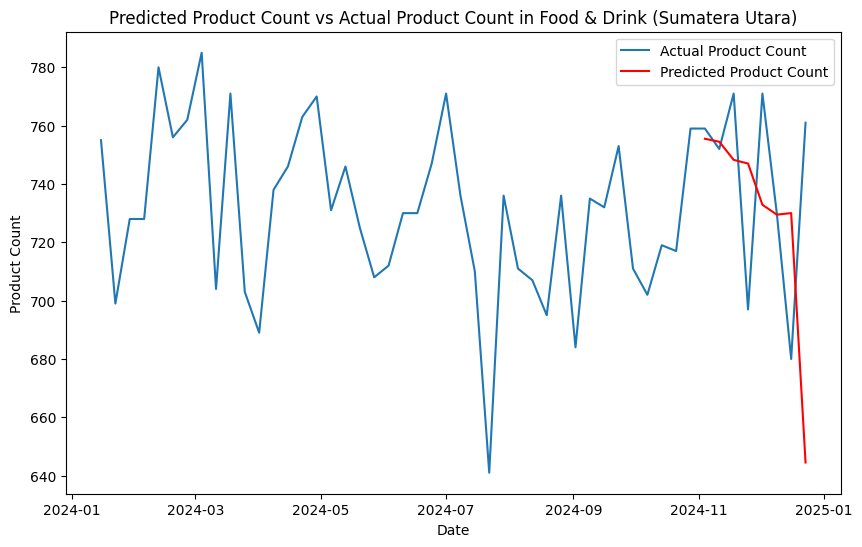

Root Mean Squared Error: 50.69892789301076


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Food & Drink'
if decomposition_fooddrink_sumut is not None:
    # Ambil dataset untuk kategori 'Food & Drink'
    data_fooddrink = datasets_sumut['Food & Drink']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_fooddrink_sumut.trend[-len(predictions_fd):]
    seasonal_component = decomposition_fooddrink_sumut.seasonal[-len(predictions_fd):]
    predictions_product_count = trend_component + seasonal_component + predictions_fd

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_fooddrink['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_fooddrink['product_count'].index, data_fooddrink['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Food & Drink (Sumatera Utara)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Food & Drink' dataset.")

In [ ]:
import pandas as pd

if decomposition_fooddrink_sumut is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumut_fd_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumut_fd_pred.head())

else:
    print("Warning: No decomposition results found for 'Food & Drink' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   759                 755.498445
1 2024-11-11                   752                 754.483656
2 2024-11-18                   771                 748.268613
3 2024-11-25                   697                 747.000808
4 2024-12-02                   771                 732.873445


In [ ]:
# Simpan DataFrame ke dalam file CSV
sumut_fd_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/sumut_fd_pred.csv', index=False)

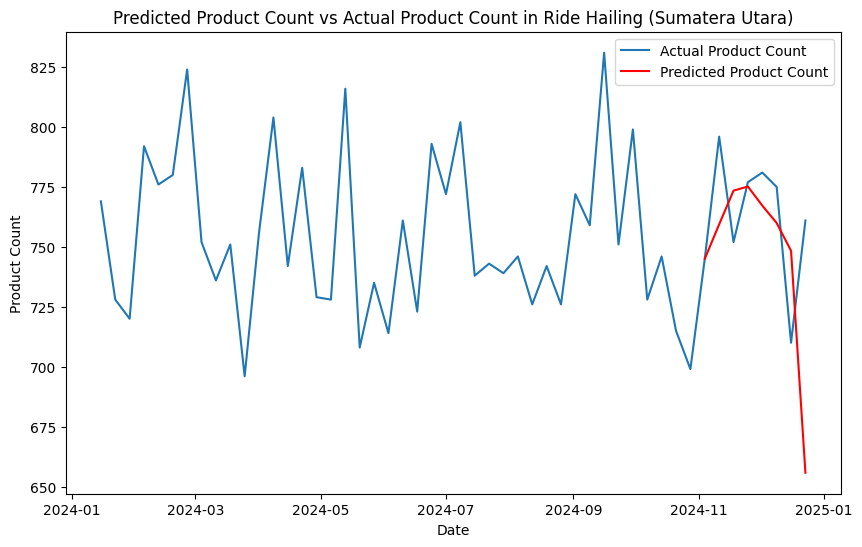

Root Mean Squared Error: 42.96244372120093


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Ride Hailing'
if decomposition_ridehailing_sumut is not None:
    # Ambil dataset untuk kategori 'Ride Hailing'
    data_ridehailing = datasets_sumut['Ride Hailing']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_ridehailing_sumut.trend[-len(predictions_rh):]
    seasonal_component = decomposition_ridehailing_sumut.seasonal[-len(predictions_rh):]
    predictions_product_count = trend_component + seasonal_component + predictions_rh

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_ridehailing['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_ridehailing['product_count'].index, data_ridehailing['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Ride Hailing (Sumatera Utara)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Ride Hailing' dataset.")


In [ ]:
import pandas as pd

if decomposition_ridehailing_sumut is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumut_rh_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumut_rh_pred.head())

else:
    print("Warning: No decomposition results found for 'Ride Hailing' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   745                 745.026271
1 2024-11-11                   796                 759.396426
2 2024-11-18                   752                 773.455758
3 2024-11-25                   777                 775.179044
4 2024-12-02                   781                 767.216566


In [ ]:
# Simpan DataFrame ke dalam file CSV
sumut_rh_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/sumut_rh_pred.csv', index=False)

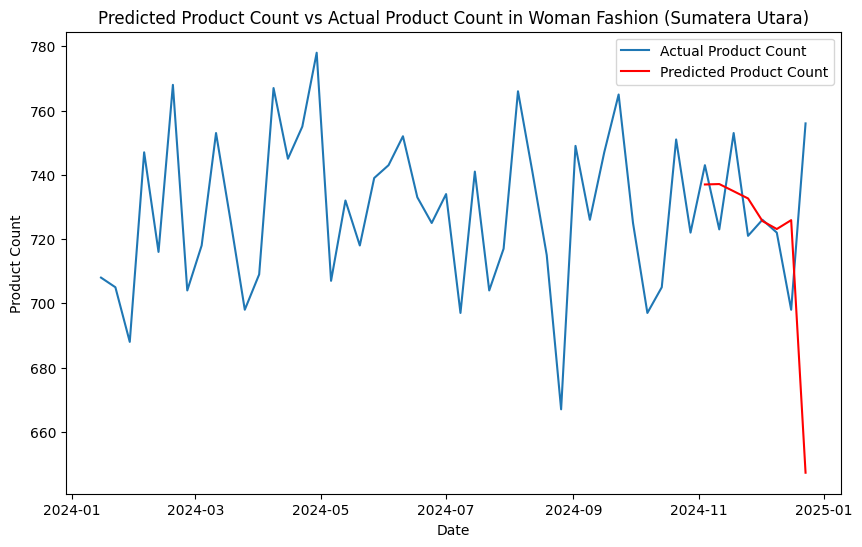

Root Mean Squared Error: 40.77494512255997


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Woman Fashion'
if decomposition_womanfashion_sumut is not None:
    # Ambil dataset untuk kategori 'Woman Fashion'
    data_wf = datasets_sumut['Woman Fashion']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_womanfashion_sumut.trend[-len(predictions_wf):]
    seasonal_component = decomposition_womanfashion_sumut.seasonal[-len(predictions_wf):]
    predictions_product_count = trend_component + seasonal_component + predictions_wf

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_womanfashion['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_wf['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_wf['product_count'].index, data_wf['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Woman Fashion (Sumatera Utara)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")

In [ ]:
import pandas as pd

if decomposition_womanfashion_sumut is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumut_wf_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumut_wf_pred.head())

else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   743                 736.990538
1 2024-11-11                   723                 737.121902
2 2024-11-18                   753                 734.883598
3 2024-11-25                   721                 732.643441
4 2024-12-02                   726                 725.615536


In [ ]:
# Simpan DataFrame ke dalam file CSV
sumut_wf_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/sumut_wf_pred.csv', index=False)

### 3. Undo Stationarity 3 Dataset berdasarkan produk dalam Sumatera Barat

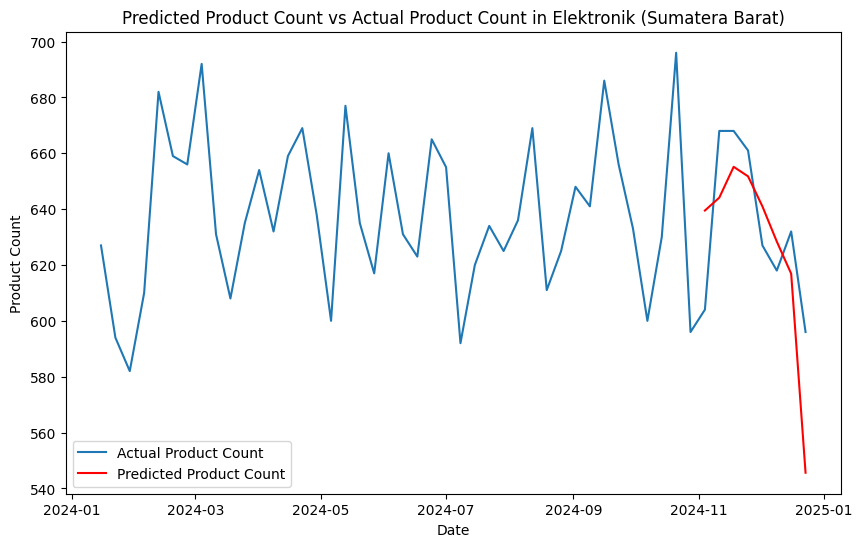

Root Mean Squared Error: 25.375734802300975


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Elektronik'
if decomposition_elektro_sumbar is not None:
    # Ambil dataset untuk kategori 'Elektronik'
    data_elektro = datasets_sumbar['Elektronik']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_elektro_sumbar.trend[-len(predictions_e):]
    seasonal_component = decomposition_elektro_sumbar.seasonal[-len(predictions_e):]
    predictions_product_count = trend_component + seasonal_component + predictions_e

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_elektro['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_elektro['product_count'].index, data_elektro['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Elektronik (Sumatera Barat)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Elektronik' dataset.")

In [ ]:
import pandas as pd

if decomposition_elektro_sumbar is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumbar_e_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumbar_e_pred.head())

else:
    print("Warning: No decomposition results found for 'Elektronik' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   604                 639.494225
1 2024-11-11                   668                 644.103700
2 2024-11-18                   668                 655.147503
3 2024-11-25                   661                 651.744485
4 2024-12-02                   627                 640.979565


In [ ]:
# Simpan DataFrame ke dalam file CSV
sumbar_e_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/sumbar_e_pred.csv', index=False)

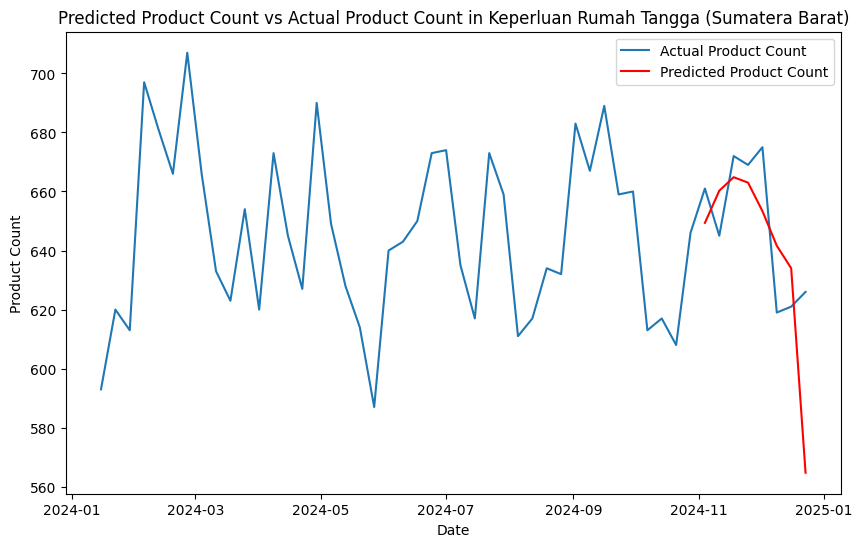

Root Mean Squared Error: 25.87417653519342


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Keperluan Rumah Tangga'
if decomposition_krt_sumbar is not None:
    # Ambil dataset untuk kategori 'Keperluan Rumah Tangga'
    data_krt = datasets_sumbar['Keperluan Rumah Tangga']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_krt_sumbar.trend[-len(predictions_krt):]
    seasonal_component = decomposition_krt_sumbar.seasonal[-len(predictions_krt):]
    predictions_product_count = trend_component + seasonal_component + predictions_krt

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_krt['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_krt['product_count'].index, data_krt['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Keperluan Rumah Tangga (Sumatera Barat)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Keperluan Rumah Tangga' dataset.")

In [ ]:
import pandas as pd

if decomposition_krt_sumbar is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumbar_krt_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumbar_krt_pred.head())

else:
    print("Warning: No decomposition results found for 'Keperluan Rumah Tangga' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   661                 649.371664
1 2024-11-11                   645                 660.256290
2 2024-11-18                   672                 664.839470
3 2024-11-25                   669                 663.001463
4 2024-12-02                   675                 653.365826


In [ ]:
# Simpan DataFrame ke dalam file CSV
sumbar_krt_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/sumbar_krt_pred.csv', index=False)

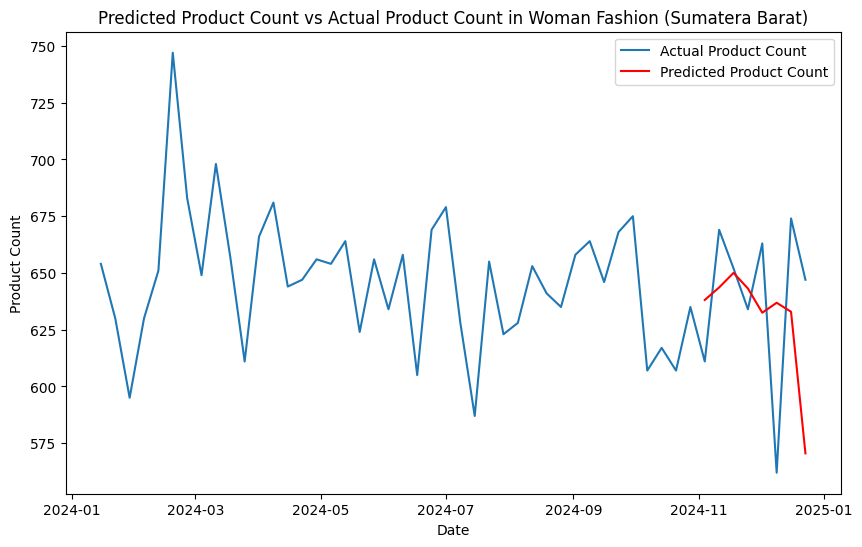

Root Mean Squared Error: 44.07594751804769


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Woman Fashion'
if decomposition_wf_sumbar is not None:
    # Ambil dataset untuk kategori 'Woman Fashion'
    data_wf = datasets_sumbar['Woman Fashion']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_wf_sumbar.trend[-len(predictions_wf):]
    seasonal_component = decomposition_wf_sumbar.seasonal[-len(predictions_wf):]
    predictions_product_count = trend_component + seasonal_component + predictions_wf

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_wf['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_wf['product_count'].index, data_wf['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Woman Fashion (Sumatera Barat)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")

In [ ]:
import pandas as pd

if decomposition_wf_sumbar is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    sumbar_wf_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(sumbar_wf_pred.head())

else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                   611                 638.098524
1 2024-11-11                   669                 643.619502
2 2024-11-18                   652                 650.024357
3 2024-11-25                   634                 643.147096
4 2024-12-02                   663                 632.473521


In [ ]:
# Simpan DataFrame ke dalam file CSV
sumbar_wf_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/sumbar_wf_pred.csv', index=False)

### 4. Undo Stationarity 3 Dataset berdasarkan produk dalam Maluku

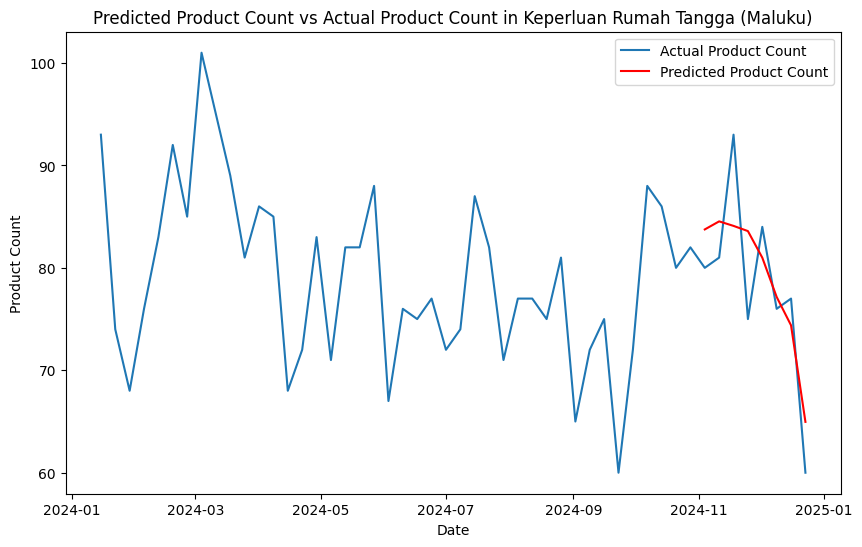

Root Mean Squared Error: 5.261419270690866


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Keperluan Rumah Tangga'
if decomposition_krt_maluku is not None:
    # Ambil dataset untuk kategori 'Keperluan Rumah Tangga'
    data_krt = datasets_maluku['Keperluan Rumah Tangga']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_krt_maluku.trend[-len(predictions_krt):]
    seasonal_component = decomposition_krt_maluku.seasonal[-len(predictions_krt):]
    predictions_product_count = trend_component + seasonal_component + predictions_krt

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_krt['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_krt['product_count'].index, data_krt['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Keperluan Rumah Tangga (Maluku)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Keperluan Rumah Tangga' dataset.")

In [ ]:
import pandas as pd

if decomposition_krt_maluku is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    maluku_krt_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(maluku_krt_pred.head())

else:
    print("Warning: No decomposition results found for 'Keperluan Rumah Tangga' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                    80                  83.749315
1 2024-11-11                    81                  84.536674
2 2024-11-18                    93                  84.094982
3 2024-11-25                    75                  83.587914
4 2024-12-02                    84                  80.993477


In [ ]:
# Simpan DataFrame ke dalam file CSV
maluku_krt_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/maluku_krt_pred.csv', index=False)

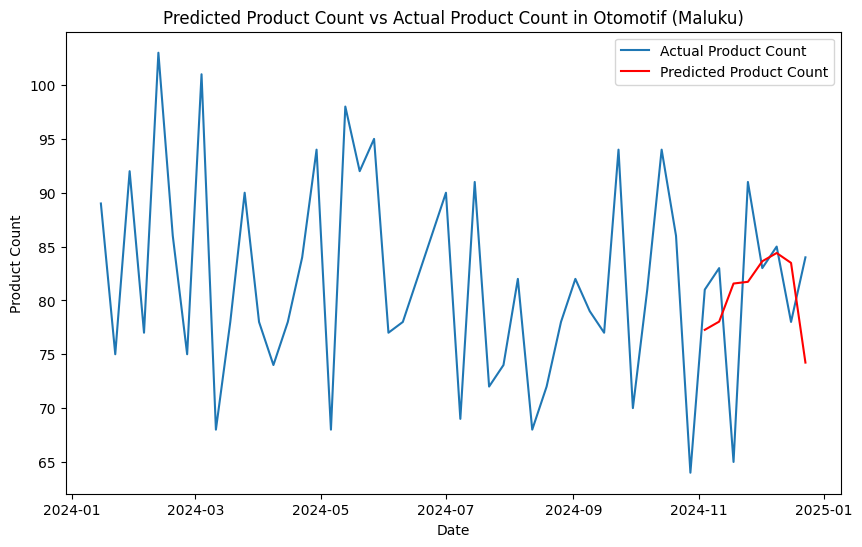

Root Mean Squared Error: 8.10457964867487


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Otomotif'
if decomposition_otomotif_maluku is not None:
    # Ambil dataset untuk kategori 'Otomotif'
    data_otomotif = datasets_maluku['Otomotif']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_otomotif_maluku.trend[-len(predictions_krt):]
    seasonal_component = decomposition_otomotif_maluku.seasonal[-len(predictions_krt):]
    predictions_product_count = trend_component + seasonal_component + predictions_krt

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_otomotif['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_otomotif['product_count'].index, data_otomotif['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Otomotif (Maluku)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Otomotif' dataset.")

In [ ]:
import pandas as pd

if decomposition_otomotif_maluku is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    maluku_otomotif_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(maluku_otomotif_pred.head())

else:
    print("Warning: No decomposition results found for 'Otomotif' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                    81                  77.267819
1 2024-11-11                    83                  78.031410
2 2024-11-18                    65                  81.568113
3 2024-11-25                    91                  81.726545
4 2024-12-02                    83                  83.636981


In [ ]:
# Simpan DataFrame ke dalam file CSV
maluku_otomotif_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/maluku_otomotif_pred.csv', index=False)

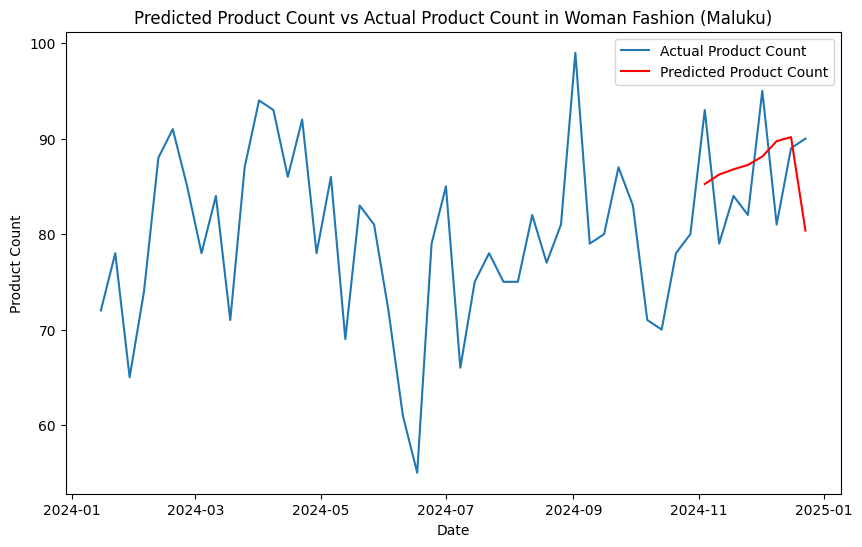

Root Mean Squared Error: 6.759175748768061


In [ ]:
# Lakukan transformasi kembali dan prediksi hanya untuk produk 'Woman Fashion'
if decomposition_wf_maluku is not None:
    # Ambil dataset untuk kategori 'Woman Fashion'
    data_wf = datasets_maluku['Woman Fashion']

    # Menggabungkan komponen trend, seasonal, dan residual untuk mendapatkan product_count
    trend_component = decomposition_wf_maluku.trend[-len(predictions_wf):]
    seasonal_component = decomposition_wf_maluku.seasonal[-len(predictions_wf):]
    predictions_product_count = trend_component + seasonal_component + predictions_wf

    # Pastikan tidak ada NaN dalam prediksi
    predictions_product_count = predictions_product_count.dropna()

    # Pastikan bagian dari data_fooddrink['product_count'] yang digunakan untuk evaluasi tidak mengandung NaN
    actual_product_count = data_wf['product_count'][-len(predictions_product_count):].dropna()

    # Pastikan panjang actual_product_count dan predictions_product_count sama
    min_length = min(len(actual_product_count), len(predictions_product_count))
    actual_product_count = actual_product_count[-min_length:]
    predictions_product_count = predictions_product_count[-min_length:]

    # Visualisasi prediksi
    plt.figure(figsize=(10, 6))
    plt.plot(data_wf['product_count'].index, data_wf['product_count'], label='Actual Product Count')
    plt.plot(predictions_product_count.index, predictions_product_count, label='Predicted Product Count', color='red')
    plt.title('Predicted Product Count vs Actual Product Count in Woman Fashion (Maluku)')
    plt.xlabel('Date')
    plt.ylabel('Product Count')
    plt.legend()
    plt.show()

    # Evaluasi kinerja model
    mse = mean_squared_error(actual_product_count, predictions_product_count)
    rmse = np.sqrt(mse)
    print("Root Mean Squared Error:", rmse)
else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")

In [ ]:
import pandas as pd

if decomposition_wf_maluku is not None:
    # Buat dataset baru yang menyimpan data date, actual_product_count, dan prediction_product_count
    maluku_wf_pred = pd.DataFrame({
        'date': actual_product_count.index,
        'actual_product_count': actual_product_count.values,
        'predictions_product_count': predictions_product_count.values
    })

    # Tampilkan dataset baru
    print(maluku_wf_pred.head())

else:
    print("Warning: No decomposition results found for 'Woman Fashion' dataset.")


        date  actual_product_count  predictions_product_count
0 2024-11-04                    93                  85.247114
1 2024-11-11                    79                  86.236364
2 2024-11-18                    84                  86.788004
3 2024-11-25                    82                  87.242996
4 2024-12-02                    95                  88.122112


In [ ]:
# Simpan DataFrame ke dalam file CSV
maluku_wf_pred.to_csv('/content/drive/MyDrive/[8A] Final Project Drive/Colab Notebooks/Forecasting Data/maluku_wf_pred.csv', index=False)